# Modelo predictivo para la clasificación y localización de aeronaves militares

### Integrantes

* Nathaly Henao
* Alejandro Perez

In [29]:
!pip install torchsummary

### Importamos las librerias requeridas:

In [30]:
from __future__ import print_function, division

import numpy as np
import pandas as pd
from numpy.typing import NDArray
from functools import reduce
from itertools import islice
import wandb
import math
from itertools import chain
import copy

import torch
from torch import nn
from torch import Tensor
from torch.optim import Optimizer

import torchvision.models as models
import torch.optim as optim

import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
from torchsummary import summary

# Import albumentations library in order to -use pre-built augmentations
import albumentations as A


from sklearn.model_selection import train_test_split
from multiprocessing import cpu_count

import os
import torch
import os.path as osp
from skimage import io, transform
import matplotlib.pyplot as plt

import matplotlib.patches as patches

import typing as ty
import cv2

plt.ion()   # interactive mode

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

for root, dirs, filenames in os.walk('/kaggle/input'):
    for i, filepath in enumerate(filenames):
        if i >= 10:
            print()
            break
        print(osp.join(root, filepath))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Creamos la estructura de datos

In [32]:
import os
import pandas as pd

# Ruta de acceso a los archivos en Google Drive
# Ruta de acceso a los archivos en Google Drive
# Directorios de los datos
DATA_DIR = '/content/drive/My Drive/FA2'
WORK_DIR = '/content/drive/My Drive/FA2'

# Cargar las imágenes
img_dir = os.path.join(DATA_DIR, 'images')  # Este es el directorio de las imágenes  # Si necesitas trabajar en un directorio específico
BATCH_SIZE = 32

# Leer el archivo CSV del entrenamiento
df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

# Mapeo de clases
obj2id  = {'f16':0,'cougar':1,'chinook':2,'ah64':3,'f15':4,'seahawk':5}

# Mapeo inverso (id a nombre de clase)
id2obj  = {0:'f16', 1:'cougar', 2:'chinook', 3:'ah64', 4:'f15', 5:'seahawk'}

# Agregar columna de class_id
df["class_id"] = df["class"].map(obj2id)

# Filtrar las columnas necesarias
columns_f = ['filename', 'xmin', 'ymin', 'xmax', 'ymax', 'class', 'class_id']
df = df[columns_f].copy()

# Revisa el DataFrame
print(df.head())


           filename  xmin  ymin  xmax  ymax    class  class_id
0  image_00373.jpeg   506   303   628   414   cougar         1
1  image_00065.jpeg   381    35   856   273  seahawk         5
2  image_00111.jpeg   467   136   830   302   cougar         1
3  image_00112.jpeg   447   122   799   287   cougar         1
4  image_00113.jpeg   418   141   631   291   cougar         1


📌EDA

Realizamos una descripción estadística de las coordenadas, evidenciando que las cajas abarcan distintas regiones de las imágenes, con variabilidad en tamaño y posición

Redimensionamos h=255 y w=400

In [33]:
df[df['xmin']>=df['xmax']].shape, df[df['ymin']>=df['ymax']].shape
h_real=720
w_real=1280
h, w, c = 255, 400, 3 # The heigh, width and number of channels of each image


In [34]:
df['class_id'].value_counts()

,count
class_id,
0,41
1,37
2,35
3,34
4,23
5,19


In [35]:
print(df[["ymin", "ymax", "xmin", "xmax"]].describe())

             ymin        ymax        xmin         xmax
count  189.000000  189.000000  189.000000   189.000000
mean   186.396825  425.455026  401.238095   902.666667
std    112.079883  103.348946  232.361996   213.588688
min      1.000000  154.000000    1.000000   298.000000
25%    109.000000  359.000000  210.000000   730.000000
50%    188.000000  417.000000  418.000000   901.000000
75%    267.000000  494.000000  572.000000  1071.000000
max    440.000000  702.000000  944.000000  1280.000000


📌Normalizamos los bboxes

Se normalizaron las columnas ymin, ymax, xmin y xmax dividiendo por las dimensiones reales de la imagen (h_real para las coordenadas verticales y w_real para las horizontales), con el objetivo de escalar todos los valores al rango [0, 1]

In [36]:
# Normalizar las columnas ymin, ymax, xmin, xmax
df[["ymin", "ymax"]] = df[["ymin", "ymax"]].div(h_real, axis=0)
df[["xmin", "xmax"]] = df[["xmin", "xmax"]].div(w_real, axis=0)

In [37]:
print(df[["ymin", "ymax", "xmin", "xmax"]].describe())

             ymin        ymax        xmin        xmax
count  189.000000  189.000000  189.000000  189.000000
mean     0.258884    0.590910    0.313467    0.705208
std      0.155667    0.143540    0.181533    0.166866
min      0.001389    0.213889    0.000781    0.232813
25%      0.151389    0.498611    0.164062    0.570312
50%      0.261111    0.579167    0.326562    0.703906
75%      0.370833    0.686111    0.446875    0.836719
max      0.611111    0.975000    0.737500    1.000000


📌Particionamiento

Dividimos el conjunto de datos en entrenamiento y validación con una proporción de 75% para entrenamiento y 25% para validación. El particionamiento fue estratificado por la variable class_id, asegurando así que la distribución de clases se mantenga representativa en ambos subconjuntos.

In [38]:
from sklearn.model_selection import train_test_split
from multiprocessing import cpu_count

train_df, val_df = train_test_split(
    df, stratify=df['class_id'], test_size=0.25, random_state=42
)

print(train_df.shape)
print(val_df.shape)

(141, 7)
(48, 7)


In [39]:
classes = df["class"].unique()
classes

array(['cougar', 'seahawk', 'ah64', 'f16', 'f15', 'chinook'], dtype=object)

In [40]:
df.head()

,filename,xmin,ymin,xmax,ymax,class,class_id
0,image_00373.jpeg,0.395313,0.420833,0.490625,0.575000,cougar,1
1,image_00065.jpeg,0.297656,0.048611,0.668750,0.379167,seahawk,5
2,image_00111.jpeg,0.364844,0.188889,0.648438,0.419444,cougar,1
3,image_00112.jpeg,0.349219,0.169444,0.624219,0.398611,cougar,1
4,image_00113.jpeg,0.326562,0.195833,0.492969,0.404167,cougar,1


In [41]:
train_df['class'].value_counts(1) * 100

,proportion
class,
f16,21.985816
cougar,19.858156
chinook,18.439716
ah64,17.730496
f15,12.056738
seahawk,9.929078


📌Cargamos el conjunto de datos de imágenes de mascotas para su procesamiento y entrenamiento usando PyTorch.

In [42]:
import typing as ty
from numpy.typing import NDArray
import numpy as np
from torch.utils.data import Dataset, DataLoader
import torch
import os
from skimage import io
import cv2


transform_func_inp_signature = ty.Dict[str, NDArray[np.float64]]
transform_func_signature = ty.Callable[
    [transform_func_inp_signature],
    transform_func_inp_signature
]

class militarDataset(Dataset):
    """
    Location image dataset
    """
    def __init__(
        self,
        df: pd.DataFrame,
        root_dir: str,
        labeled: bool = True,
        transform: ty.Optional[ty.List[transform_func_signature]] = None,
        output_size: ty.Optional[tuple] = None
    ) -> None:
        self.df = df
        self.root_dir = root_dir
        self.transform = transform
        self.labeled = labeled
        self.output_size = output_size

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, idx: int) -> transform_func_signature:
        if torch.is_tensor(idx):
            idx = idx.tolist()

        # Read image
        img_name = os.path.join(self.root_dir, self.df.filename.iloc[idx])
        image = io.imread(img_name)

        if image is None:
            raise FileNotFoundError(f"Image not found: {img_name}")

        if image.ndim == 2:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        elif image.shape[2] == 4:
            image = image[:, :, :3]

        if self.output_size:
            image = cv2.resize(image, self.output_size)

        sample = {'image': image}

        if self.labeled:
            # Read labels
            img_class = self.df.class_id.iloc[idx]
            img_bbox = self.df.iloc[idx, 1:5]

            # Create one-hot encoding for class_id
            num_classes = 6  # Total number of classes
            img_class_one_hot = np.zeros(num_classes, dtype=np.float32)
            img_class_one_hot[img_class] = 1

            img_bbox = np.array([img_bbox]).astype('float')
            sample.update({'bbox': img_bbox, 'class_id': img_class_one_hot})

        if self.transform:
            sample = self.transform(sample)

        return sample

📌Definición de funciones para dibujar las bounding boxes y las etiquetas de clases en las imagenes

In [43]:
def draw_bbox(img, bbox, color,thickness: int = 3):
    xmin, ymin, xmax, ymax = bbox
    img = cv2.rectangle(img, (xmin, ymin), (xmax, ymax), color, thickness)
    return img

def normalize_bbox(bbox, h: int, w: int):
    """Escala las coordenadas normalizadas al tamaño real de la imagen."""
    return [
        int(bbox[0] * w),  # xmin
        int(bbox[1] * h),  # ymin
        int(bbox[2] * w),  # xmax
        int(bbox[3] * h),  # ymax
    ]

    # Asegúrate de que las coordenadas de las cajas delimitadoras estén dentro del rango de la imagen
def clip_bbox_to_image(bbox, h, w):
    """Asegura que las coordenadas de las cajas estén dentro de los límites de la imagen."""
    return np.clip(bbox, 0, [w, h, w, h])

def draw_bboxes(imgs, bboxes, colors,thickness):
    """Dibuja múltiples cuadros delimitadores en imágenes, escalando según h y w."""
    for i, (img, bbox, color) in enumerate(zip(imgs, bboxes, colors)):
        imgs[i] = draw_bbox(img, bbox, color,thickness)
    return imgs

def draw_classes(imgs, classes, colors, origin, prefix: str ='',fontScale : int = 2):
    """Dibuja las clases en las imágenes."""
    for i, (img, class_id, color) in enumerate(zip(imgs, classes, colors)):
        if type(c)==list:
            name_class_=id2obj[classes[i]]
        else:
            name_class_=id2obj[classes[i][0]]
        imgs[i] = cv2.putText(
            img, f'{prefix}{name_class_}', #class_id.squeeze()
            origin, cv2.FONT_HERSHEY_SIMPLEX,
            fontScale , color, 2, cv2.LINE_AA
        )
    return imgs

def draw_predictions(imgs, classes, bboxes, colors, origin,thickness,fontScale):
    """
    Combina las funciones anteriores para dibujar cuadros delimitadores
    y clases en las imágenes.
    """
    assert all(len(x) > 0 for x in [imgs, classes, bboxes, colors])
    if len(colors) == 1:
        colors = [colors[0] for _ in imgs]
    imgs = draw_bboxes(imgs, bboxes, colors,thickness)
    imgs = draw_classes(imgs, classes, colors, origin,"",fontScale)
    return imgs

📌Visualizacion de las imágenes con las cajas delimitadoras(bounding boxes) y las clases

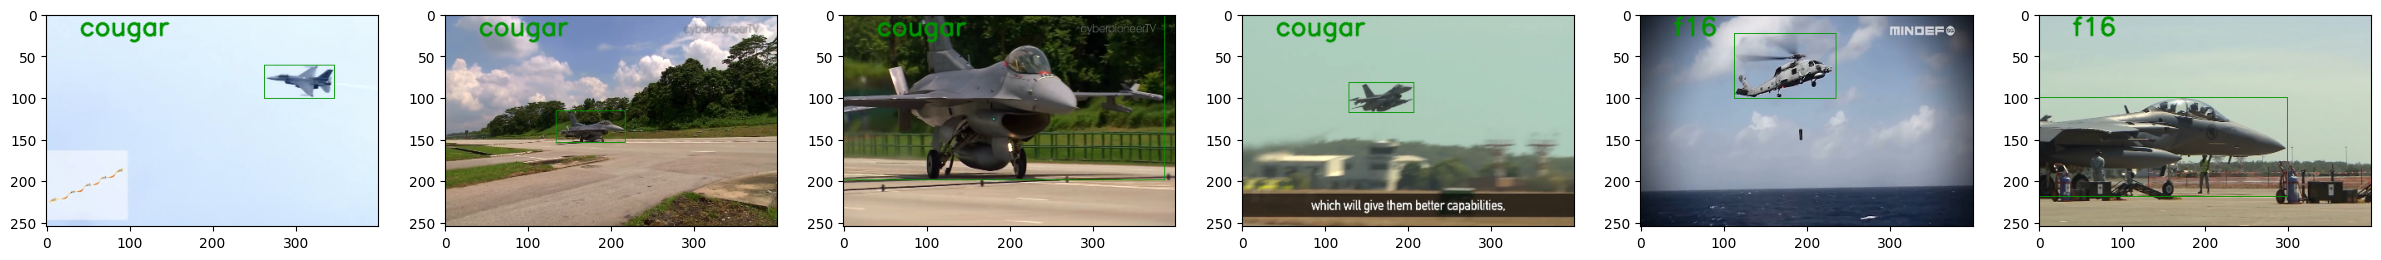

In [44]:
import os.path as osp
from torch.utils.data import Dataset, DataLoader
import torch # import torch module
from skimage import io
import cv2 # Import cv2 here
import matplotlib.pyplot as plt

train_root_dir = osp.join(DATA_DIR, "images")#, "train"
train_ds = militarDataset(train_df, root_dir=train_root_dir,output_size=(w,h))

num_imgs = 6
start_idx = 0

samples = [train_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze(),h,w) for s in samples]
classes = [s['class_id'] for s in samples]

imgs = draw_predictions(imgs, classes, bboxes, [(0, 150, 0)], (int(w*0.1), int(h*0.1)),thickness = 1,fontScale=1)#(150, 10)

fig = plt.figure(figsize=(30, num_imgs))

for i, img in enumerate(imgs):
    fig.add_subplot(1, num_imgs, i+1)
    plt.imshow(img)

plt.show()

📌 Cálculo de medias y desviaciones estándar de los valores de los píxeles en los canales de color del conjunto de datos de imágenes para su posterior normalización.

In [45]:
train_ds = militarDataset(train_df, root_dir=train_root_dir,output_size=(w,h))

means = np.zeros(3)
stds = np.zeros(3)
n_images = 0

for x in train_ds:
    img = x['image']#.astype(np.float32)  # Asegúrate de que la imagen está en float para cálculos precisos
    n_images += 1

    for channel in range(3):
        channel_pixels = img[..., channel]
        # Acumular la suma y suma de cuadrados para calcular la media y desviación estándar
        means[channel] += np.mean(channel_pixels)
        stds[channel] += np.std(channel_pixels)

# Calcular la media y desviación estándar final
means /= n_images
stds /= n_images

In [46]:
print(means)
print(stds)

[136.01424392 148.27792699 157.09680045]
[48.72264438 48.96054089 52.18792645]


📌Definición de Transformaciones de preprocesamiento a las imágenes:  tensores, normalizacións y Torch Vision.

In [47]:
class ToTensor(object):
    """Convert ndarrays in sample to Tensors."""

    def __call__(self, sample):
        image = sample['image']

        # swap color axis because
        # numpy image: H x W x C (0,1,2)
        # torch image: C x H x W
        image = image.transpose((2, 0, 1))
        image = torch.from_numpy(image).float()
        sample.update({'image': image})
        return sample

class Normalizer(object):

    def __init__(self, stds, means):
        """
        Arguments:

            stds: array of length 3 containing the standard deviation of each channel in RGB order.
            means: array of length 3 containing the means of each channel in RGB order.
        """
        self.stds = stds
        self.means = means

    def __call__(self, sample):
        """
        Sample: a dicitonary containing:
            image: sample image in format (C, H, W)
        Returns:
            the image in (C, H, W) format with the channels normalized.
        """
        image = sample['image']

        for channel in range(3):
            image[channel] = (image[channel] - means[channel]) / stds[channel]

        sample['image'] = image
        return sample

class TVTransformWrapper(object):
    """Torch Vision Transform Wrapper
    """
    def __init__(self, transform: torch.nn.Module):
        self.transform = transform

    def __call__(self, sample):
        sample['image'] = self.transform(sample['image'])
        return sample

class AlbumentationsWrapper(object):

    def __init__(self, transform):
        self.transform = transform

    def __call__(self, sample):
        transformed = self.transform(
            image=sample['image'],
            bboxes=sample['bbox'],
            #category_ids=sample['class_id']
        )
        sample['image'] = transformed['image']
        sample['bbox'] = np.array(transformed['bboxes'])
        return sample


📌Preparación los datos tanto en el conjunto de entrenamiento como en el conjunto de evaluación

In [48]:
common_transforms = [
    ToTensor(),
    Normalizer(
        means=means,
        stds=stds,
    )
]
train_transforms = torchvision.transforms.Compose(common_transforms)
eval_transforms = torchvision.transforms.Compose(common_transforms)

📌Preparamos el conjunto de datos de entrenamiento, se divididen estos en batchs y muestra las dimensiones de las imágenes del primer batch para asegurarnos de que se carguen adecuadamente

In [49]:
train_ds = militarDataset(train_df, root_dir=train_root_dir, transform=train_transforms,output_size=(w,h))#
train_data = torch.utils.data.DataLoader(train_ds, batch_size=32)#,collate_fn=custom_collate_fn

for x in train_data:
    print(x['image'].size())
    break

torch.Size([32, 3, 255, 400])


In [50]:
eval_ds = militarDataset(val_df, root_dir=train_root_dir, transform=eval_transforms,output_size=(w,h))
eval_data = torch.utils.data.DataLoader(eval_ds, batch_size=32)

for x in eval_data:
    print(x['image'].size())
    break

torch.Size([32, 3, 255, 400])


###✅CNN PERSONALIZADO

In [51]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()

        # Backbone (Extractor de Características)
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce a la mitad

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce a la mitad

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce a la mitad

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce a la mitad

            nn.Flatten()
        )

        # Ajustamos el tamaño de la entrada para las capas totalmente conectadas
        self.fc_common = nn.Sequential(
            nn.Linear(256 * 15 * 25, 512),  # Aquí usamos 15x25 en lugar de 16x16
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        # Cabeza de Regresión (Bounding Box)
        self.bbox_head = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 4),
        )

        # Cabeza de Clasificación (ahora con 6 clases)
        self.classification_head = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 6),  # 6 clases en lugar de 1
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.fc_common(x)
        bbox_output = self.bbox_head(x)
        class_output = self.classification_head(x)
        return bbox_output, class_output


In [52]:
#Ajuste de la inicialización de los Pesos
def init_weights(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.kaiming_uniform_(m.weight)
        if m.bias is not None:
            m.bias.data.fill_(0.01)

model = CustomCNN()
model.apply(init_weights)

CustomCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [53]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

CustomCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

📌Función para calcular el IoU entre pares de cajas delimitadoras

In [54]:
def calculate_iou(box1, box2):
    x1 = torch.max(box1[:, 0], box2[:, 0])
    y1 = torch.max(box1[:, 1], box2[:, 1])
    x2 = torch.min(box1[:, 2], box2[:, 2])
    y2 = torch.min(box1[:, 3], box2[:, 3])

    intersection = torch.clamp(x2 - x1, min=0) * torch.clamp(y2 - y1, min=0)
    area_box1 = (box1[:, 2] - box1[:, 0]) * (box1[:, 3] - box1[:, 1])
    area_box2 = (box2[:, 2] - box2[:, 0]) * (box2[:, 3] - box2[:, 1])
    union = area_box1 + area_box2 - intersection

    iou = intersection / union
    return iou


In [55]:
#Entrenamiento del Modelo Personalizado
train_iou_sum = 0
eval_iou_sum = 0

train_losses = []
train_accuracies = []
eval_losses = []
eval_accuracies = []
train_iou_scores = []
eval_iou_scores = []

# Definición de las Funciones de Pérdida
bbox_loss_fn = nn.SmoothL1Loss()  # Pérdida para las cajas delimitadoras
classification_loss_fn = nn.CrossEntropyLoss()  # Pérdida para clasificación multiclase

# Definición del Optimizador + Regularización L2
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

# Inicialización de la mejor precisión
mejor_precision = 0
mejor_loss = float('inf')

# Entrenamiento del Modelo
num_epochs = 100
print_interval = 10

for epoch in range(num_epochs):
    # Fase de entrenamiento
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    for batch in train_data:
        images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
        images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

        predicted_bboxes, predicted_labels = model(images)

        if bboxes.dim() == 3 and bboxes.size(1) == 1:
            bboxes = bboxes.squeeze(1)

        loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
        # Get class indices from one-hot encoded labels
        labels_indices = torch.argmax(labels, dim=1)
        loss_classification = classification_loss_fn(predicted_labels, labels_indices)  # Usar CrossEntropy para clasificación multiclase
        total_loss = loss_bbox + loss_classification

        # Obtener la clase predicha como la clase con la mayor probabilidad
        _, predicted_classes = torch.max(predicted_labels, 1)
        # Compare predicted classes with class indices
        correct_predictions += (predicted_classes == labels_indices).sum().item()
        total_predictions += labels.size(0)

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()

    epoch_loss = running_loss / len(train_data)
    epoch_accuracy = correct_predictions / total_predictions
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    iou = calculate_iou(predicted_bboxes, bboxes)
    train_iou_sum += iou.sum().item()
    train_iou = train_iou_sum / total_predictions
    train_iou_scores.append(train_iou)

    # Fase de validación
    model.eval()
    eval_loss = 0.0
    correct_eval_predictions = 0
    total_eval_predictions = 0

    with torch.no_grad():
        for batch in eval_data:
            # The following lines were not indented correctly.
            images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
            images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

            predicted_bboxes, predicted_labels = model(images)

            if bboxes.dim() == 3 and bboxes.size(1) == 1:
                bboxes = bboxes.squeeze(1)

            loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
            # Get class indices from one-hot encoded labels
            labels_indices = torch.argmax(labels, dim=1)
            loss_classification = classification_loss_fn(predicted_labels, labels_indices)  # Usar CrossEntropy para clasificación multiclase
            total_loss_eval = loss_bbox + loss_classification

            # Obtener la clase predicha como la clase con la mayor probabilidad
            _, predicted_classes = torch.max(predicted_labels, 1)
            # Compare predicted classes with class indices
            correct_eval_predictions += (predicted_classes == labels_indices).sum().item()
            total_eval_predictions += labels.size(0)

            eval_loss += total_loss_eval.item()

    eval_losses.append(eval_loss / len(eval_data))
    eval_accuracies.append(correct_eval_predictions / total_eval_predictions)

    iou = calculate_iou(predicted_bboxes, bboxes)
    eval_iou_sum += iou.sum().item()
    eval_iou = eval_iou_sum / total_eval_predictions
    eval_iou_scores.append(eval_iou)

    # Guardar el modelo si la precisión de validación es la mejor hasta ahora y el menor loss como segunda condición
    if eval_accuracies[-1] > mejor_precision or (eval_accuracies[-1] == mejor_precision and eval_losses[-1] < mejor_loss):
        mejor_precision = eval_accuracies[-1]
        mejor_loss = eval_losses[-1]
        torch.save(model.state_dict(), 'mejor_modelo.pth')

    # Impresión de Resultados
    if (epoch + 1) % print_interval == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}] => '
              f'Train loss: {epoch_loss:.4f}, Train accuracy: {epoch_accuracy:.4f}, Train IoU: {train_iou:.4f}, '
              f'Eval loss: {eval_losses[-1]:.4f}, Eval accuracy: {eval_accuracies[-1]:.4f}, Eval IoU: {eval_iou:.4f}')

    train_iou_sum = 0
    eval_iou_sum = 0

print("¡Entrenamiento Completo!")


Epoch [10/100] => Train loss: 1.2481, Train accuracy: 0.7730, Train IoU: 0.0013, Eval loss: 1.0304, Eval accuracy: 0.7292, Eval IoU: 0.0070
Epoch [20/100] => Train loss: 0.6858, Train accuracy: 0.9220, Train IoU: 0.0000, Eval loss: 0.8312, Eval accuracy: 0.7292, Eval IoU: 0.0114
Epoch [30/100] => Train loss: 0.5931, Train accuracy: 0.9716, Train IoU: 0.0025, Eval loss: 0.8143, Eval accuracy: 0.7292, Eval IoU: 0.0070
Epoch [40/100] => Train loss: 0.5118, Train accuracy: 0.9716, Train IoU: 0.0004, Eval loss: 0.7243, Eval accuracy: 0.7917, Eval IoU: 0.0148
Epoch [50/100] => Train loss: 0.4712, Train accuracy: 0.9433, Train IoU: 0.0018, Eval loss: 0.6890, Eval accuracy: 0.7708, Eval IoU: 0.0064
Epoch [60/100] => Train loss: 0.3380, Train accuracy: 0.9787, Train IoU: 0.0014, Eval loss: 0.7476, Eval accuracy: 0.7500, Eval IoU: 0.0141
Epoch [70/100] => Train loss: 0.3380, Train accuracy: 0.9716, Train IoU: 0.0016, Eval loss: 0.6993, Eval accuracy: 0.7708, Eval IoU: 0.0093
Epoch [80/100] => Tr

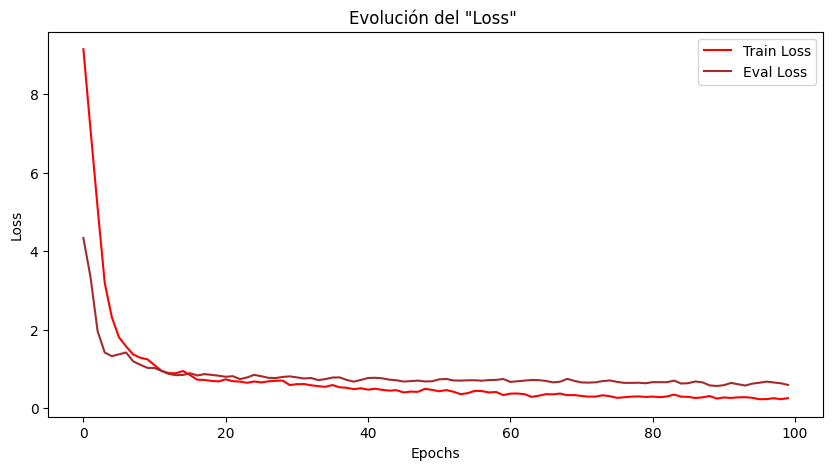

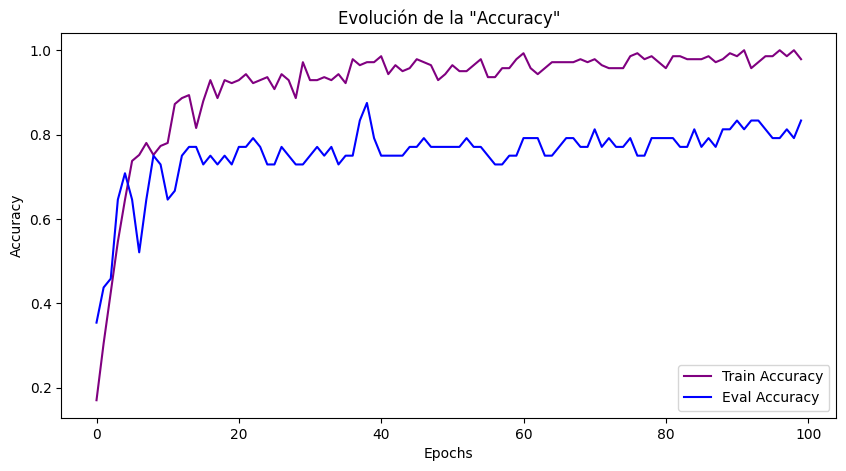

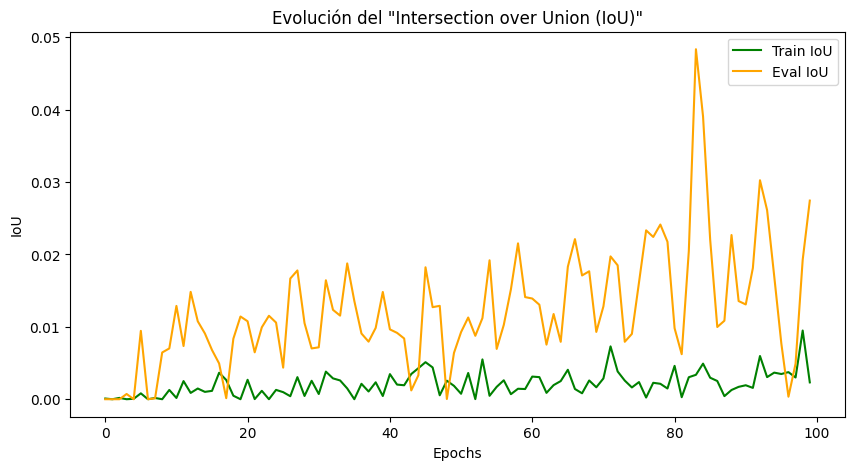

In [56]:
# Evolución del Loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(eval_losses, label='Eval Loss', color='brown')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Evolución del "Loss" ')
plt.legend()
plt.show()

# Evolución del Accuracy
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label='Train Accuracy', color='purple')
plt.plot(eval_accuracies, label='Eval Accuracy', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Evolución de la "Accuracy"')
plt.legend()
plt.show()

# Evolución del IoU
plt.figure(figsize=(10, 5))
plt.plot(train_iou_scores, label='Train IoU', color='green')
plt.plot(eval_iou_scores, label='Eval IoU', color='orange')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.title('Evolución del "Intersection over Union (IoU)"')
plt.legend()
plt.show()

In [57]:
#Preparación Visualización Clases y bboxes predichas VS. Reales

# Cargar el mejor modelo
model.load_state_dict(torch.load('mejor_modelo.pth'))
model.eval()

num_imgs = 8
ncols = 8
nrows = math.ceil(num_imgs / ncols)

start_idx = 0
inference_ds = militarDataset(val_df.iloc[start_idx:start_idx+num_imgs], root_dir=train_root_dir,output_size=(w,h))
inference_data = DataLoader(inference_ds, batch_size=num_imgs, num_workers=0, shuffle=False)
inference_batch = next(iter(inference_data))
inference_imgs = np.empty((num_imgs, 3, 255, 400))

transform = eval_transforms

for i, img in enumerate(inference_batch['image']):
    inference_imgs[i] = transform(dict(image=img.numpy()))['image'].numpy()

preds = model(torch.tensor(inference_imgs).float().to(device))

samples = [inference_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze(), h, w) for s in samples]
classes = [s['class_id'] for s in samples]

# Obtener predicciones del modelo
predicted_bboxes, predicted_labels = model(torch.tensor(inference_imgs).float().to(device))

pred_bboxes = predicted_bboxes.detach().cpu().numpy()
pred_bboxes = [normalize_bbox(bbox, h, w) for bbox in pred_bboxes] # Added h and w arguments
# Get predicted class index for each image
pred_classes = torch.argmax(predicted_labels, dim=1).detach().cpu().numpy()

Imagen 0: bbox real [127, 46, 271, 160], clase real seahawk
Imagen 0: bbox predicha [-22, 134, 141, 90], clase predicha seahawk


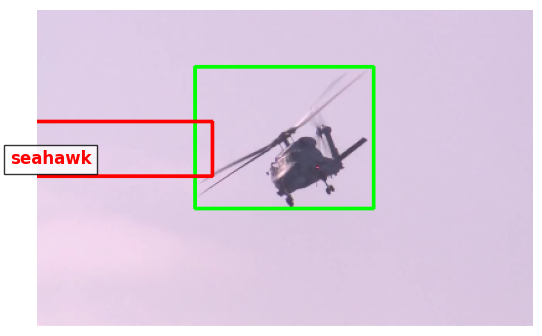

Imagen 1: bbox real [216, 92, 261, 121], clase real f15
Imagen 1: bbox predicha [120, 3, 251, -85], clase predicha f15


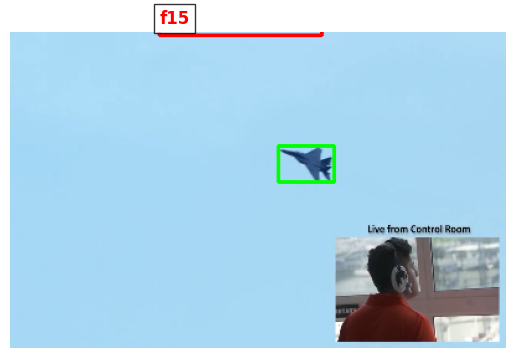

Imagen 2: bbox real [158, 25, 222, 89], clase real f15
Imagen 2: bbox predicha [210, 75, 408, 36], clase predicha f15


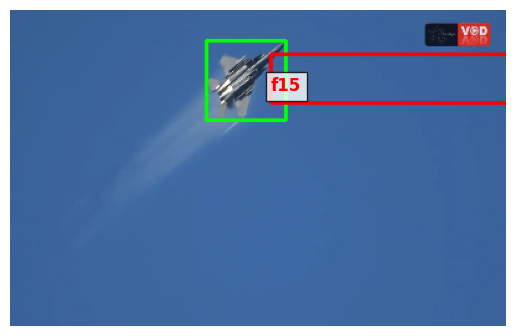

Imagen 3: bbox real [213, 130, 287, 165], clase real chinook
Imagen 3: bbox predicha [71, -37, 18, 72], clase predicha chinook


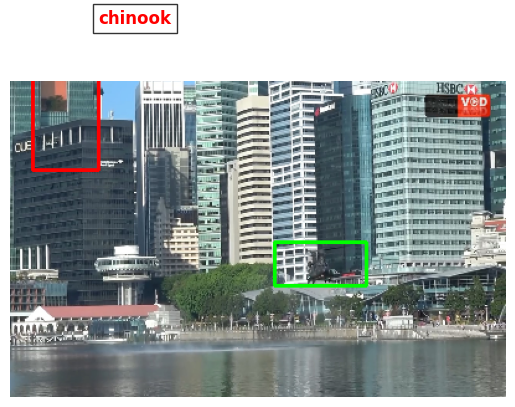

Imagen 4: bbox real [45, 35, 282, 160], clase real cougar
Imagen 4: bbox predicha [-65, 171, 158, 116], clase predicha cougar


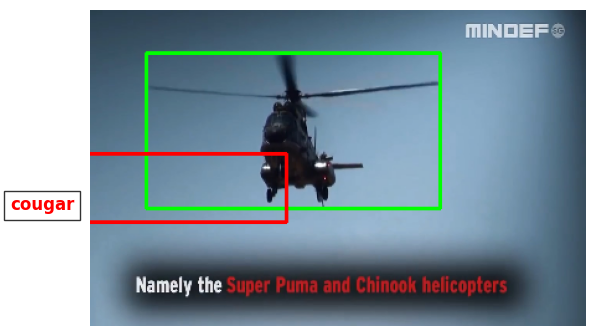

Imagen 5: bbox real [23, 66, 238, 181], clase real cougar
Imagen 5: bbox predicha [-76, 72, 82, 50], clase predicha ah64


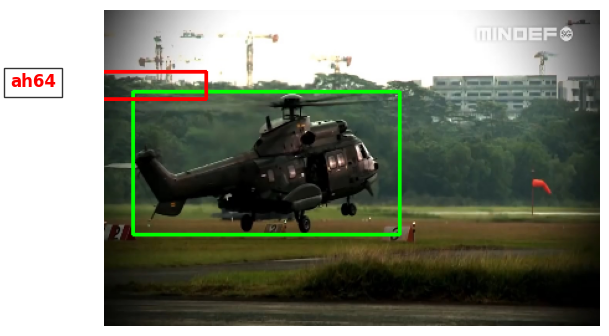

Imagen 6: bbox real [207, 139, 300, 184], clase real chinook
Imagen 6: bbox predicha [1, -53, 80, 237], clase predicha chinook


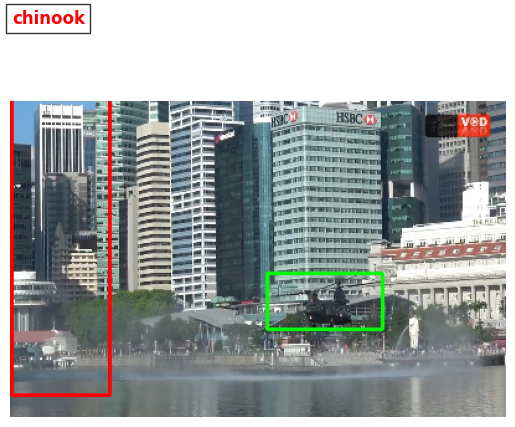

Imagen 7: bbox real [28, 80, 199, 180], clase real f16
Imagen 7: bbox predicha [-424, 123, 143, 159], clase predicha f16


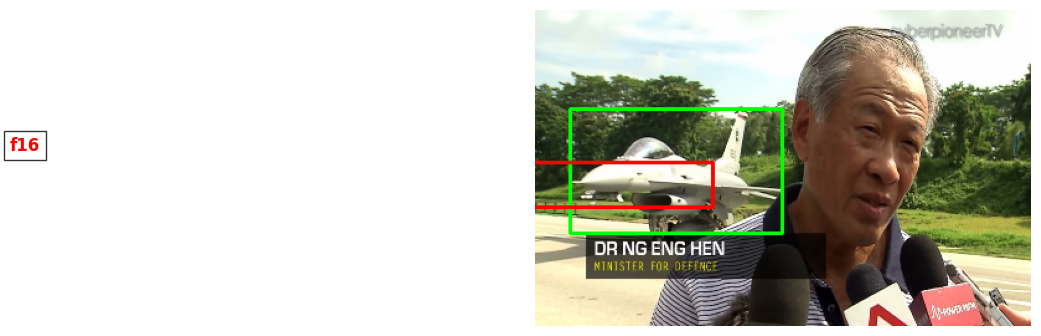

In [58]:
import matplotlib.pyplot as plt

for i, (img, pred_bbox, pred_class, real_bbox, real_class) in enumerate(zip(imgs, pred_bboxes, pred_classes, bboxes, classes)):
    # Obtener el nombre de la clase predicha usando id2obj
    pred_class_name = id2obj[pred_class]
    real_class_name = id2obj[np.argmax(real_class)] #added line

    print(f"Imagen {i}: bbox real {real_bbox}, clase real {real_class_name}")
    print(f"Imagen {i}: bbox predicha {pred_bbox}, clase predicha {pred_class_name}")

    # Dibuja la bounding box real (verde)
    img_with_bboxes = draw_bbox(img.copy(), real_bbox, color=(0, 255, 0), thickness=2)
    # Dibuja la bounding box predicha (rojo)
    img_with_bboxes = draw_bbox(img_with_bboxes, pred_bbox, color=(255, 0, 0), thickness=2)

    # Agrega una etiqueta con la clase predicha
    plt.imshow(img_with_bboxes)
    plt.text(
        pred_bbox[0],  # Posición x del texto (esquina superior izquierda de la bbox predicha)
        pred_bbox[1] - 10,  # Posición y del texto (un poco arriba de la bbox predicha)
        f'{pred_class_name}',  # Texto a mostrar (nombre de la clase predicha)
        color='red',  # Color del texto
        fontsize=12,  # Tamaño de la fuente
        weight='bold',  # Grosor de la fuente
        bbox=dict(facecolor='white', alpha=0.8)  # Fondo blanco detrás del texto
    )
    plt.axis('off')  # Ocultar los ejes
    plt.show()

📈CONCLUSIONES

Se desarrolló y entrenó una red neuronal convolucional personalizada, CustomCNN, con una arquitectura de doble salida: una cabeza de regresión para predecir las bounding boxes y otra de clasificación para identificar la clase del objeto entre 6 categoría.
  
Durante el entrenamiento, el modelo logró una alta precisión en clasificación, alcanzando hasta 97% de exactitud en entrenamiento y 87.5% en validación, lo que evidencia una buena capacidad para diferenciar entre clases. Sin embargo, los resultados del IoU se mantuvieron bajos (en promedio por debajo de 0.02), lo que indica que la red aún presenta dificultades al momento de ajustar con precisión las cajas delimitadoras.  Las predicciones visuales confirman este hallazgo: las clases suelen ser correctas, pero las bounding boxes no siempre se alinean bien con el objeto real.

In [59]:
# Preparación Para los Submit
# Change device to 'cpu' if no GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# The rest of your code remains the same
test_root_dir = osp.join(DATA_DIR, "images")
test_df = pd.read_csv(osp.join(DATA_DIR, "test.csv"))

# Asegúrate de que el dataset de prueba tenga las transformaciones adecuadas aplicadas
test_ds = militarDataset(test_df, root_dir=test_root_dir, labeled=False, transform=eval_transforms,output_size=(w,h))#
test_data = DataLoader(test_ds, batch_size=1, num_workers=cpu_count(), shuffle=False)

class_preds = []
bbox_preds = []

# Iterar sobre el conjunto de datos de prueba
for batch in test_data:
    # Mover imágenes al dispositivo correcto
    images = batch['image'].float().to(device)

    # Obtener predicciones del modelo
    predicted_bboxes, predicted_labels = model(images)

    # Get the predicted class index
    _, predicted_class_index = torch.max(predicted_labels, 1)

    # Create one-hot encoding for predicted class
    class_pred_binario = torch.zeros(6)  # 6 classes
    class_pred_binario[predicted_class_index] = 1
    class_pred_binario = class_pred_binario.detach().cpu().numpy()

    # Extraer las predicciones de las bounding boxes y mover a CPU
    bbox_pred = predicted_bboxes.detach().cpu().numpy()

    # Aplanar las predicciones si están en un lote de tamaño 1
    class_preds.append(class_pred_binario.squeeze())
    bbox_preds.append(bbox_pred.squeeze())


In [60]:
class_preds = np.array(class_preds)
bbox_preds = np.array(bbox_preds)

In [61]:
submission = pd.DataFrame(
    index=test_df.filename,
    data={
        'class_id': [np.argmax(pred) for pred in class_preds], # Get the index of the highest probability for each image
    }
)
submission

,class_id
filename,
image_00219.jpeg,2
image_00034.jpeg,0
image_00265.jpeg,3
image_00042.jpeg,0
image_00294.jpeg,3
...,...
image_00035.jpeg,0
image_00071.jpeg,1
image_00099.jpeg,2


In [62]:
submission["xmin"] = bbox_preds[:, 0]*w_real
submission["ymin"] = bbox_preds[:, 1]*h_real
submission["xmax"] = bbox_preds[:, 2]*w_real
submission["ymax"] = bbox_preds[:, 3]*h_real

In [63]:
submission['class_id']=submission['class_id'].replace(id2obj)

In [64]:
submission.to_csv('/content/drive/MyDrive/FA/submissionintentov1_Intu.csv')

In [65]:
##Limpiar Cache
torch.cuda.empty_cache()

###✅TRANSFER LEARNING

Para esta etapa, implementamos una arquitectura de doble backbone, integrando dos redes convolucionales preentrenadas: ResNet18 y EfficientNet-B0

In [66]:
import torch
import torch.nn as nn
import torchvision.models as models

class DualBackboneModel(nn.Module):
    def __init__(self):
        super(DualBackboneModel, self).__init__()

        # Backbone 1: ResNet18
        self.backbone1 = models.resnet18(pretrained=True)
        self.backbone1 = nn.Sequential(*list(self.backbone1.children())[:-1])  # Quitar la capa de clasificación

        # Backbone 2: EfficientNet
        self.backbone2 = models.efficientnet_b0(pretrained=True)
        self.backbone2 = nn.Sequential(*list(self.backbone2.children())[:-1])  # Quitar la capa de clasificación

        # Cabeza de clasificación
        self.classification_head = nn.Sequential(
            nn.Linear(512 + 1280, 256),  # Combina las salidas de ambos backbones
            nn.ReLU(),
            nn.Linear(256, 6),  # 6 clases
            nn.Softmax(dim=1)
        )

        # Cabeza de regresión (bounding boxes)
        self.bbox_head = nn.Sequential(
            nn.Linear(512 + 1280, 256),
            nn.ReLU(),
            nn.Linear(256, 4)  # Coordenadas xmin, ymin, xmax, ymax
        )

    def forward(self, x):
        # Extraer características de ambos backbones
        features1 = self.backbone1(x)
        features1 = features1.view(features1.size(0), -1)  # Aplanar

        features2 = self.backbone2(x)
        features2 = features2.view(features2.size(0), -1)  # Aplanar

        # Combinar características
        combined_features = torch.cat((features1, features2), dim=1)

        # Pasar a las cabezas
        bbox_output = self.bbox_head(combined_features)
        class_output = self.classification_head(combined_features)

        return bbox_output, class_output

In [67]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DualBackboneModel().to(device)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed i

In [68]:
# Entrenamiento del Modelo ResNet18 Customizado ==> Transfer Learning
train_iou_sum = 0
eval_iou_sum = 0

train_losses = []
train_accuracies = []
eval_losses = []
eval_accuracies = []
train_iou_scores = []
eval_iou_scores = []

# Definición de las Funciones de Pérdida
bbox_loss_fn = nn.SmoothL1Loss()  # Para las bounding boxes
classification_loss_fn = nn.CrossEntropyLoss()  # Para clasificación multiclase

# Definición del Optimizador + Regularización L2
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

# Inicialización de la mejor precisión
mejor_precision = 0
mejor_loss = float('inf')

# Entrenamiento del Modelo
num_epochs = 100
print_interval = 10

for epoch in range(num_epochs):
    # Fase de entrenamiento
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    for batch in train_data:
        images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
        images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

        # Forward pass
        predicted_bboxes, predicted_labels = model(images)

        # Asegurar que las dimensiones de las bounding boxes sean correctas
        if bboxes.dim() == 3 and bboxes.size(1) == 1:
            bboxes = bboxes.squeeze(1)

        # Cálculo de las pérdidas
        loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
        loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))  # Usar índices de clase
        total_loss = loss_bbox + loss_classification

        # Predicciones y métricas
        _, predicted_classes = torch.max(predicted_labels, 1)  # Clase con mayor probabilidad
        correct_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
        total_predictions += labels.size(0)

        # Backward pass y optimización
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()

    # Métricas de entrenamiento
    epoch_loss = running_loss / len(train_data)
    epoch_accuracy = correct_predictions / total_predictions
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    iou = calculate_iou(predicted_bboxes, bboxes)
    train_iou_sum += iou.sum().item()
    train_iou = train_iou_sum / total_predictions
    train_iou_scores.append(train_iou)

    # Fase de validación
    model.eval()
    eval_loss = 0.0
    correct_eval_predictions = 0
    total_eval_predictions = 0

    with torch.no_grad():
        for batch in eval_data:
            images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
            images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

            # Forward pass
            predicted_bboxes, predicted_labels = model(images)

            # Asegurar que las dimensiones de las bounding boxes sean correctas
            if bboxes.dim() == 3 and bboxes.size(1) == 1:
                bboxes = bboxes.squeeze(1)

            # Cálculo de las pérdidas
            loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
            loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))  # Usar índices de clase
            total_loss_eval = loss_bbox + loss_classification

            # Predicciones y métricas
            _, predicted_classes = torch.max(predicted_labels, 1)  # Clase con mayor probabilidad
            correct_eval_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
            total_eval_predictions += labels.size(0)

            eval_loss += total_loss_eval.item()

    # Métricas de validación
    eval_losses.append(eval_loss / len(eval_data))
    eval_accuracies.append(correct_eval_predictions / total_eval_predictions)

    iou = calculate_iou(predicted_bboxes, bboxes)
    eval_iou_sum += iou.sum().item()
    eval_iou = eval_iou_sum / total_eval_predictions
    eval_iou_scores.append(eval_iou)

    # Guardar el modelo si la precisión de validación es la mejor hasta ahora
    if eval_accuracies[-1] > mejor_precision or (eval_accuracies[-1] == mejor_precision and eval_losses[-1] < mejor_loss):
        mejor_precision = eval_accuracies[-1]
        mejor_loss = eval_losses[-1]
        torch.save(model.state_dict(), 'mejor_modelo_rn.pth')

    # Impresión de resultados
    if (epoch + 1) % print_interval == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}] => '
              f'Train loss: {epoch_loss:.4f}, Train accuracy: {epoch_accuracy:.4f}, Train IoU: {train_iou:.4f}, '
              f'Eval loss: {eval_losses[-1]:.4f}, Eval accuracy: {eval_accuracies[-1]:.4f}, Eval IoU: {eval_iou:.4f}')

    # Reiniciar acumuladores de IoU
    train_iou_sum = 0
    eval_iou_sum = 0

print("¡Entrenamiento Completo!")

Epoch [10/100] => Train loss: 1.0685, Train accuracy: 1.0000, Train IoU: 0.0511, Eval loss: 1.2357, Eval accuracy: 0.8750, Eval IoU: 0.1220
Epoch [20/100] => Train loss: 1.0457, Train accuracy: 1.0000, Train IoU: 0.0712, Eval loss: 1.2133, Eval accuracy: 0.8542, Eval IoU: 0.1213
Epoch [30/100] => Train loss: 1.0447, Train accuracy: 1.0000, Train IoU: 0.0721, Eval loss: 1.2082, Eval accuracy: 0.8542, Eval IoU: 0.1169
Epoch [40/100] => Train loss: 1.0444, Train accuracy: 1.0000, Train IoU: 0.0716, Eval loss: 1.2041, Eval accuracy: 0.8542, Eval IoU: 0.1170
Epoch [50/100] => Train loss: 1.0442, Train accuracy: 1.0000, Train IoU: 0.0781, Eval loss: 1.1995, Eval accuracy: 0.8542, Eval IoU: 0.1148
Epoch [60/100] => Train loss: 1.0440, Train accuracy: 1.0000, Train IoU: 0.0783, Eval loss: 1.2015, Eval accuracy: 0.8542, Eval IoU: 0.1129
Epoch [70/100] => Train loss: 1.0440, Train accuracy: 1.0000, Train IoU: 0.0814, Eval loss: 1.2015, Eval accuracy: 0.8542, Eval IoU: 0.1117
Epoch [80/100] => Tr

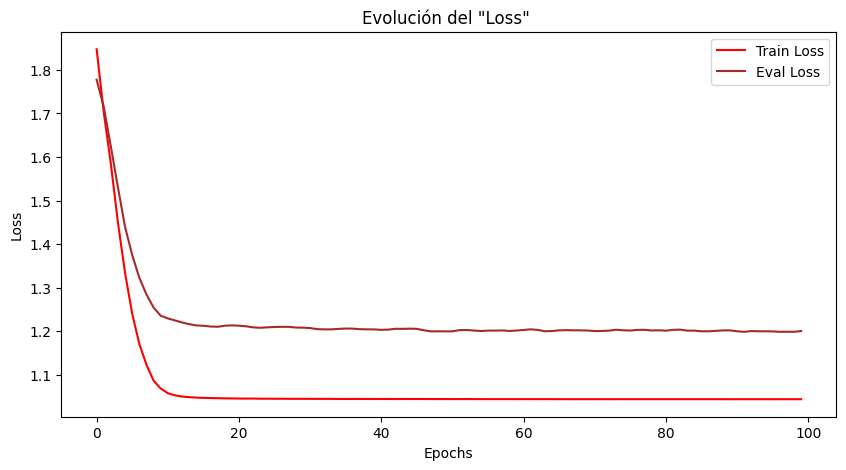

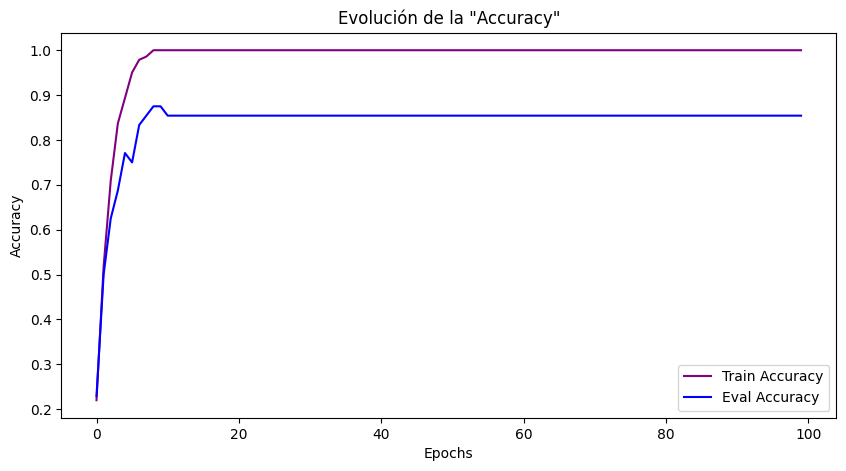

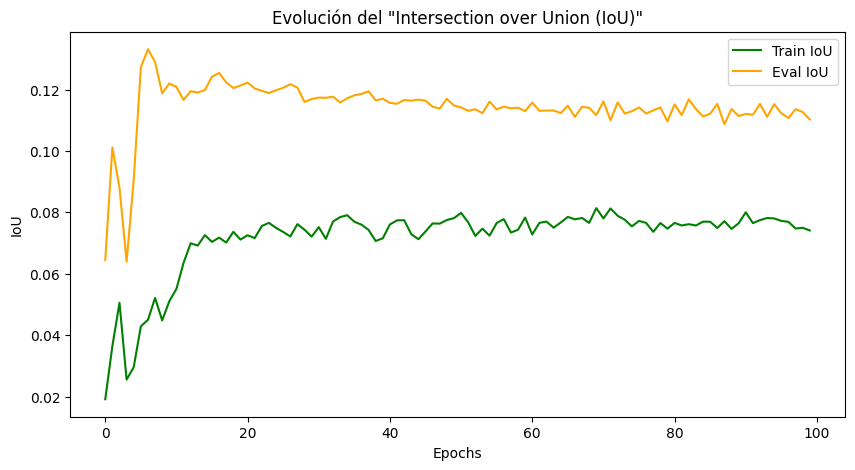

In [69]:
# Evolución del Loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(eval_losses, label='Eval Loss', color='brown')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Evolución del "Loss" ')
plt.legend()
plt.show()

# Evolución del Accuracy
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label='Train Accuracy', color='purple')
plt.plot(eval_accuracies, label='Eval Accuracy', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Evolución de la "Accuracy"')
plt.legend()
plt.show()

# Evolución del IoU
plt.figure(figsize=(10, 5))
plt.plot(train_iou_scores, label='Train IoU', color='green')
plt.plot(eval_iou_scores, label='Eval IoU', color='orange')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.title('Evolución del "Intersection over Union (IoU)"')
plt.legend()
plt.show()

In [70]:
###Preparación Visualización Clases y bboxes predichas VS. Reales

# Cargar el mejor modelo
model.load_state_dict(torch.load('mejor_modelo_rn.pth'))
model.eval()

num_imgs = 8
ncols = 8
nrows = math.ceil(num_imgs / ncols)

start_idx = 0
inference_ds = militarDataset(val_df.iloc[start_idx:start_idx+num_imgs], root_dir=train_root_dir,output_size=(w,h))
inference_data = DataLoader(inference_ds, batch_size=num_imgs, num_workers=1, shuffle=False)
inference_batch = next(iter(inference_data))
inference_imgs = np.empty((num_imgs, 3, 255, 400))

transform = eval_transforms

for i, img in enumerate(inference_batch['image']):
    inference_imgs[i] = transform(dict(image=img.numpy()))['image'].numpy()

preds = model(torch.tensor(inference_imgs).float().to(device))

samples = [inference_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze(), h, w) for s in samples]
classes = [s['class_id'] for s in samples]

# Obtener predicciones del modelo
predicted_bboxes, predicted_labels = model(torch.tensor(inference_imgs).float().to(device))

pred_bboxes = predicted_bboxes.detach().cpu().numpy()
pred_bboxes = [normalize_bbox(bbox, h, w) for bbox in pred_bboxes] # Added h and w arguments
# Get predicted class index for each image
pred_classes = torch.argmax(predicted_labels, dim=1).detach().cpu().numpy()

Imagen 0: bbox real [127, 46, 271, 160], clase real seahawk
Imagen 0: bbox predicha [188, 23, 291, 160], clase predicha seahawk


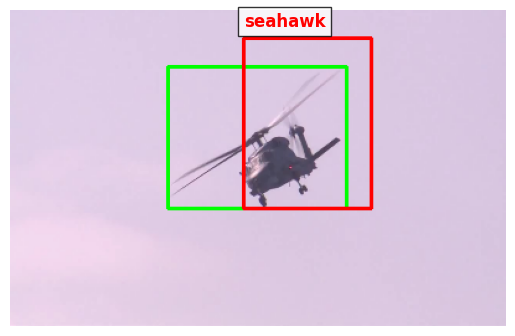

Imagen 1: bbox real [216, 92, 261, 121], clase real f15
Imagen 1: bbox predicha [155, 68, 233, 115], clase predicha f15


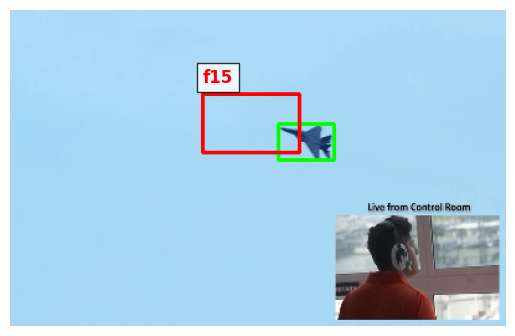

Imagen 2: bbox real [158, 25, 222, 89], clase real f15
Imagen 2: bbox predicha [204, 63, 271, 102], clase predicha f15


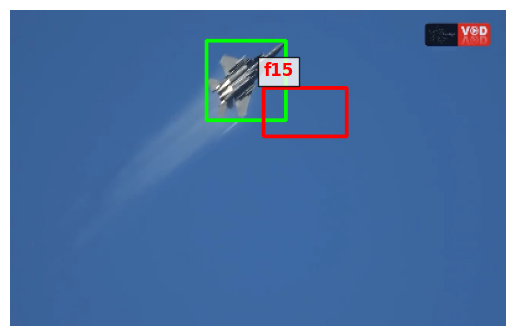

Imagen 3: bbox real [213, 130, 287, 165], clase real chinook
Imagen 3: bbox predicha [219, 131, 300, 183], clase predicha chinook


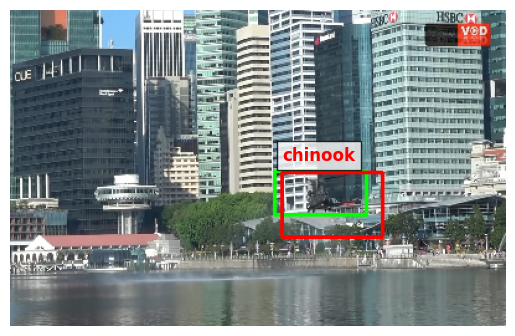

Imagen 4: bbox real [45, 35, 282, 160], clase real cougar
Imagen 4: bbox predicha [115, 8, 366, 149], clase predicha cougar


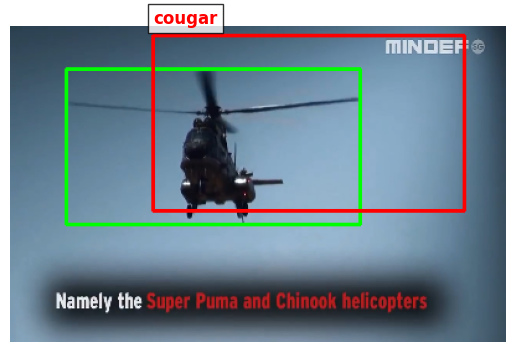

Imagen 5: bbox real [23, 66, 238, 181], clase real cougar
Imagen 5: bbox predicha [55, 39, 227, 121], clase predicha ah64


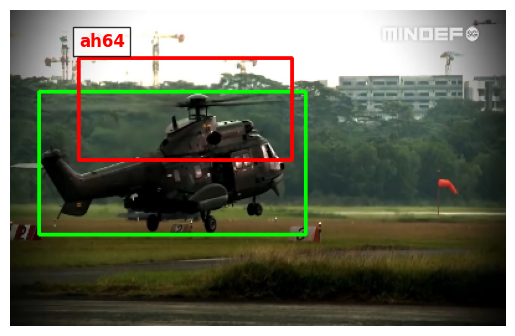

Imagen 6: bbox real [207, 139, 300, 184], clase real chinook
Imagen 6: bbox predicha [227, 141, 294, 184], clase predicha chinook


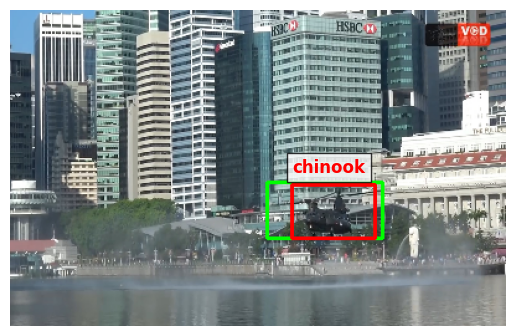

Imagen 7: bbox real [28, 80, 199, 180], clase real f16
Imagen 7: bbox predicha [91, 41, 250, 162], clase predicha f16


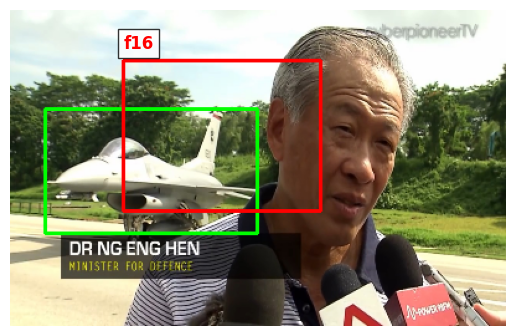

In [71]:
import matplotlib.pyplot as plt

for i, (img, pred_bbox, pred_class, real_bbox, real_class) in enumerate(zip(imgs, pred_bboxes, pred_classes, bboxes, classes)):
    # Obtener el nombre de la clase predicha usando id2obj
    pred_class_name = id2obj[pred_class]
    real_class_name = id2obj[np.argmax(real_class)] #added line

    print(f"Imagen {i}: bbox real {real_bbox}, clase real {real_class_name}")
    print(f"Imagen {i}: bbox predicha {pred_bbox}, clase predicha {pred_class_name}")

    # Dibuja la bounding box real (verde)
    img_with_bboxes = draw_bbox(img.copy(), real_bbox, color=(0, 255, 0), thickness=2)
    # Dibuja la bounding box predicha (rojo)
    img_with_bboxes = draw_bbox(img_with_bboxes, pred_bbox, color=(255, 0, 0), thickness=2)

    # Agrega una etiqueta con la clase predicha
    plt.imshow(img_with_bboxes)
    plt.text(
        pred_bbox[0],  # Posición x del texto (esquina superior izquierda de la bbox predicha)
        pred_bbox[1] - 10,  # Posición y del texto (un poco arriba de la bbox predicha)
        f'{pred_class_name}',  # Texto a mostrar (nombre de la clase predicha)
        color='red',  # Color del texto
        fontsize=12,  # Tamaño de la fuente
        weight='bold',  # Grosor de la fuente
        bbox=dict(facecolor='white', alpha=0.8)  # Fondo blanco detrás del texto
    )
    plt.axis('off')  # Ocultar los ejes
    plt.show()

📈CONCLUSIONES

El modelo alcanzó un 100% de precisión en entrenamiento y una precisión estable del 85.4% en validación, lo cual refleja una buena capacidad de generalización en tareas de clasificación multiclase. Sin embargo puede presentarse el caso de que exista sobreajuste.

El modelo logró una mejora significativa en el desempeño espacial, con un IoU de validación promedio de 0.107, superando claramente el modelo CNN personalizado previo. Las cajas predichas se aproximan de manera más a las reales, aunque aún se observan desviaciones extremas.

In [72]:
### Preparación Para los Submit
# Change device to 'cpu' if no GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# The rest of your code remains the same
test_root_dir = osp.join(DATA_DIR, "images")
test_df = pd.read_csv(osp.join(DATA_DIR, "test.csv"))

# Asegúrate de que el dataset de prueba tenga las transformaciones adecuadas aplicadas
test_ds = militarDataset(test_df, root_dir=test_root_dir, labeled=False, transform=eval_transforms,output_size=(w,h))#
test_data = DataLoader(test_ds, batch_size=1, num_workers=cpu_count(), shuffle=False)

class_preds = []
bbox_preds = []

# Iterar sobre el conjunto de datos de prueba
for batch in test_data:
    # Mover imágenes al dispositivo correcto
    images = batch['image'].float().to(device)

    # Obtener predicciones del modelo
    predicted_bboxes, predicted_labels = model(images)

    # Get the predicted class index
    _, predicted_class_index = torch.max(predicted_labels, 1)

    # Create one-hot encoding for predicted class
    class_pred_binario = torch.zeros(6)  # 6 classes
    class_pred_binario[predicted_class_index] = 1
    class_pred_binario = class_pred_binario.detach().cpu().numpy()

    # Extraer las predicciones de las bounding boxes y mover a CPU
    bbox_pred = predicted_bboxes.detach().cpu().numpy()

    # Aplanar las predicciones si están en un lote de tamaño 1
    class_preds.append(class_pred_binario.squeeze())
    bbox_preds.append(bbox_pred.squeeze())

In [73]:
class_preds = np.array(class_preds)
bbox_preds = np.array(bbox_preds)

In [74]:
submission = pd.DataFrame(
    index=test_df.filename,
    data={
        'class_id': [np.argmax(pred) for pred in class_preds], # Get the index of the highest probability for each image
    }
)
submission

,class_id
filename,
image_00219.jpeg,2
image_00034.jpeg,0
image_00265.jpeg,3
image_00042.jpeg,0
image_00294.jpeg,3
...,...
image_00035.jpeg,0
image_00071.jpeg,3
image_00099.jpeg,2


In [75]:
submission["xmin"] = bbox_preds[:, 0]*w_real
submission["ymin"] = bbox_preds[:, 1]*h_real
submission["xmax"] = bbox_preds[:, 2]*w_real
submission["ymax"] = bbox_preds[:, 3]*h_real

In [76]:
submission['class_id']=submission['class_id'].replace(id2obj)

In [77]:
submission.to_csv('/content/drive/MyDrive/FA/submissionintentov2_Intu.csv')

In [78]:
##Limpiar Cache
torch.cuda.empty_cache()

###✅DATA AUGMENTATION


In [79]:
#### Transformaciones Integrando Data Augmentation
class ToTensor(object):
    """Convert ndarrays in sample to Tensors."""

    def __call__(self, sample):
        image = sample['image']

        # swap color axis because
        # numpy image: H x W x C (0,1,2)
        # torch image: C x H x W
        image = image.transpose((2, 0, 1))
        image = torch.from_numpy(image).float()
        sample.update({'image': image})
        return sample

class Normalizer(object):

    def __init__(self, stds, means):
        """
        Arguments:

            stds: array of length 3 containing the standard deviation of each channel in RGB order.
            means: array of length 3 containing the means of each channel in RGB order.
        """
        self.stds = stds
        self.means = means

    def __call__(self, sample):
        """
        Sample: a dicitonary containing:
            image: sample image in format (C, H, W)
        Returns:
            the image in (C, H, W) format with the channels normalized.
        """
        image = sample['image']

        for channel in range(3):
            image[channel] = (image[channel] - means[channel]) / stds[channel]

        sample['image'] = image
        return sample

class TVTransformWrapper(object):
    """Torch Vision Transform Wrapper
    """
    def __init__(self, transform: torch.nn.Module):
        self.transform = transform

    def __call__(self, sample):
        sample['image'] = self.transform(sample['image'])
        return sample

class AlbumentationsWrapper(object):

    def __init__(self, transform):
        self.transform = transform

    def __call__(self, sample):
        transformed = self.transform(
            image=sample['image'],
            bboxes=sample['bbox'],
            #category_ids=sample['class_id']
        )
        sample['image'] = transformed['image']
        sample['bbox'] = np.array(transformed['bboxes'])
        return sample

In [80]:
!pip install -U albumentations

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 367.1/367.1 kB 11.7 MB/s eta 0:00:00
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.6
    Uninstalling albumentations-2.0.6:
      Successfully uninstalled albumentations-2.0.6


In [81]:
common_transforms = [
    ToTensor(),
    Normalizer(
        means=means,
        stds=stds,
    )
]

train_data_augmentations = A.Compose([
    A.HorizontalFlip(p=0.5),      # Los animales pueden orientarse hacia cualquier lado
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),    # Ajustes de iluminación
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2, p=0.5),     # Variaciones de color
    A.Rotate(limit=(-20, 20), p=0.5, border_mode=cv2.BORDER_CONSTANT),    # Rotaciones leves
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5, border_mode=cv2.BORDER_CONSTANT),  # Transformaciones afines
    A.Resize(height=255, width=400, p=1),  # Redimensionar siempre para mantener la consistencia del tamaño de entrada
    # A.Cutout(num_holes=8, max_h_size=16, max_w_size=16, p=0.5),  # Recorte aleatorio de parches
    A.GaussNoise(var_limit=(10, 50), p=0.5),  # Ruido Gaussiano
    # Asegúrate de que las transformaciones se apliquen a las bounding boxes también
    ],
    bbox_params=A.BboxParams(
        format='albumentations',
        label_fields=[],#'category_ids'
    )
)

train_transforms = torchvision.transforms.Compose(
    [
        AlbumentationsWrapper(train_data_augmentations),
    ] + common_transforms
)

eval_transforms = torchvision.transforms.Compose(common_transforms)

/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:111: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
<ipython-input-81-e031ba701301>:17: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10, 50), p=0.5),  # Ruido Gaussiano


In [82]:
## Datos de Entrenamiento con Data Augmentation
train_ds_t = militarDataset(df, root_dir=train_root_dir, transform=train_transforms)
train_data_t = torch.utils.data.DataLoader(train_ds_t, batch_size=32)

for x in train_data_t:
    print(x['image'].size())
    break

torch.Size([32, 3, 255, 400])


In [83]:
## Datos de Evaluacion con las tranformaciones "normales" (no se debe incluir Data Augmentation)
eval_ds = militarDataset(val_df, root_dir=train_root_dir, transform=eval_transforms,output_size=(w,h))
eval_data = torch.utils.data.DataLoader(eval_ds, batch_size=32)

for x in eval_data:
    print(x['image'].size())
    break

torch.Size([32, 3, 255, 400])


In [84]:
### CNN Personalizado
#Ajuste de la inicialización de los Pesos
def init_weights(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.kaiming_uniform_(m.weight)
        if m.bias is not None:
            m.bias.data.fill_(0.01)

model = CustomCNN()
model.apply(init_weights)

CustomCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [85]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

CustomCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [86]:
# Entrenamiento del Modelo Personalizado + Data Augmentation
train_iou_sum = 0
eval_iou_sum = 0

train_losses = []
train_accuracies = []
eval_losses = []
eval_accuracies = []
train_iou_scores = []
eval_iou_scores = []

# Definición las Funciones de Pérdida
bbox_loss_fn = nn.SmoothL1Loss()
classification_loss_fn = nn.CrossEntropyLoss()  # Cambiado a CrossEntropyLoss para clasificación multiclase

# Definición el Optimizador + Regularización L2
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

# Inicialización de la mejor precisión
mejor_precision = 0
mejor_loss = float('inf')

# Entrenamiento del Modelo
num_epochs = 100
print_interval = 10

for epoch in range(num_epochs):
    # Fase de entrenamiento
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    for batch in train_data_t:
        images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
        images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

        predicted_bboxes, predicted_labels = model(images)

        if bboxes.dim() == 3 and bboxes.size(1) == 1:
            bboxes = bboxes.squeeze(1)

        # Cálculo de las pérdidas
        loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
        loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))  # Usar índices de clase
        total_loss = loss_bbox + loss_classification

        # Predicciones y métricas
        _, predicted_classes = torch.max(predicted_labels, 1)  # Clase con mayor probabilidad
        correct_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
        total_predictions += labels.size(0)

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()

    epoch_loss = running_loss / len(train_data_t)
    epoch_accuracy = correct_predictions / total_predictions
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    iou = calculate_iou(predicted_bboxes, bboxes)
    train_iou_sum += iou.sum().item()
    train_iou = train_iou_sum / total_predictions
    train_iou_scores.append(train_iou)

    # Fase de validación
    model.eval()
    eval_loss = 0.0
    correct_eval_predictions = 0
    total_eval_predictions = 0

    with torch.no_grad():
        for batch in eval_data:
            images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
            images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

            predicted_bboxes, predicted_labels = model(images)

            if bboxes.dim() == 3 and bboxes.size(1) == 1:
                bboxes = bboxes.squeeze(1)

            # Cálculo de las pérdidas
            loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
            loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))  # Usar índices de clase
            total_loss_eval = loss_bbox + loss_classification

            # Predicciones y métricas
            _, predicted_classes = torch.max(predicted_labels, 1)  # Clase con mayor probabilidad
            correct_eval_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
            total_eval_predictions += labels.size(0)

            eval_loss += total_loss_eval.item()

    eval_losses.append(eval_loss / len(eval_data))
    eval_accuracies.append(correct_eval_predictions / total_eval_predictions)

    iou = calculate_iou(predicted_bboxes, bboxes)
    eval_iou_sum += iou.sum().item()
    eval_iou = eval_iou_sum / total_eval_predictions
    eval_iou_scores.append(eval_iou)

    # Guardar el modelo si la precisión de validación es la mejor hasta ahora y el menor loss como segunda condición
    if eval_accuracies[-1] > mejor_precision or (eval_accuracies[-1] == mejor_precision and eval_losses[-1] < mejor_loss):
        mejor_precision = eval_accuracies[-1]
        mejor_loss = eval_losses[-1]
        torch.save(model.state_dict(), 'mejor_modelo_pda.pth')

    # Impresión de Resultados
    if (epoch + 1) % print_interval == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}] => '
              f'Train loss: {epoch_loss:.4f}, Train accuracy: {epoch_accuracy:.4f}, Train IoU: {train_iou:.4f}, '
              f'Eval loss: {eval_losses[-1]:.4f}, Eval accuracy: {eval_accuracies[-1]:.4f}, Eval IoU: {eval_iou:.4f}')

    train_iou_sum = 0
    eval_iou_sum = 0

print("¡Entrenamiento Completo!")

Epoch [10/100] => Train loss: 1.8709, Train accuracy: 0.2328, Train IoU: 0.0051, Eval loss: 1.8059, Eval accuracy: 0.3125, Eval IoU: 0.0061
Epoch [20/100] => Train loss: 1.8631, Train accuracy: 0.2275, Train IoU: 0.0007, Eval loss: 1.8065, Eval accuracy: 0.3542, Eval IoU: 0.0028
Epoch [30/100] => Train loss: 1.8228, Train accuracy: 0.3122, Train IoU: 0.0056, Eval loss: 1.6800, Eval accuracy: 0.3958, Eval IoU: 0.0172
Epoch [40/100] => Train loss: 1.7714, Train accuracy: 0.2910, Train IoU: 0.0058, Eval loss: 1.6792, Eval accuracy: 0.3958, Eval IoU: 0.0213
Epoch [50/100] => Train loss: 1.7185, Train accuracy: 0.3228, Train IoU: 0.0069, Eval loss: 1.6247, Eval accuracy: 0.4583, Eval IoU: 0.0115
Epoch [60/100] => Train loss: 1.7529, Train accuracy: 0.2804, Train IoU: 0.0140, Eval loss: 1.5534, Eval accuracy: 0.5000, Eval IoU: 0.0192
Epoch [70/100] => Train loss: 1.6815, Train accuracy: 0.2963, Train IoU: 0.0043, Eval loss: 1.4762, Eval accuracy: 0.5000, Eval IoU: 0.0159
Epoch [80/100] => Tr

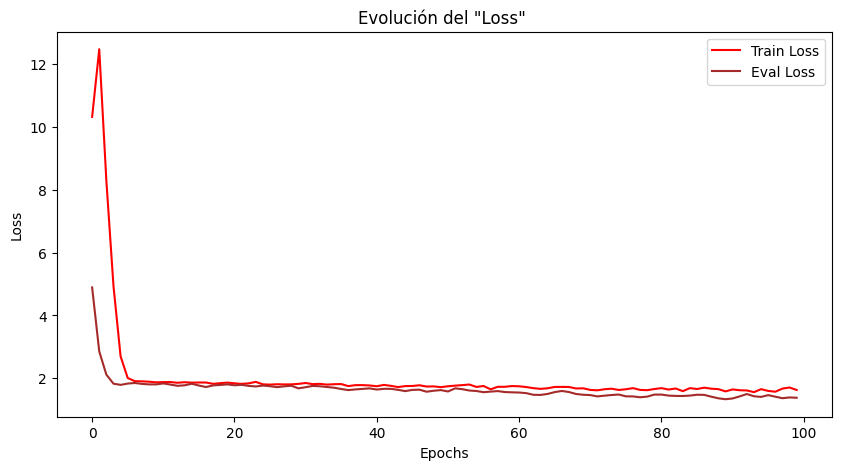

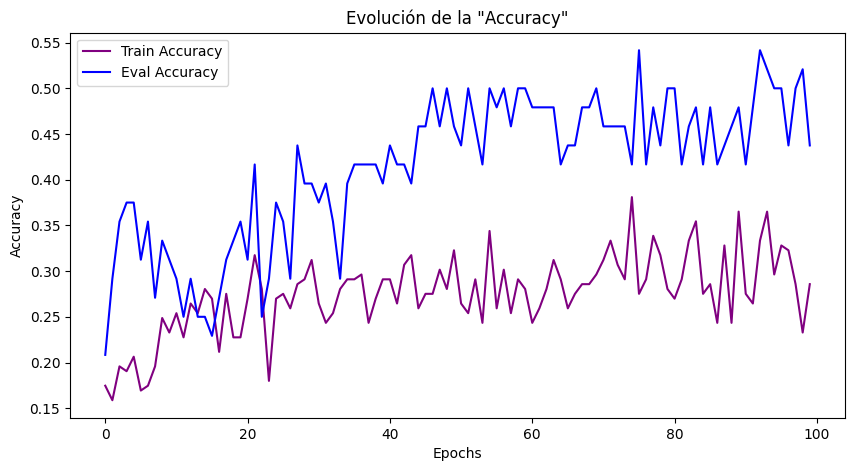

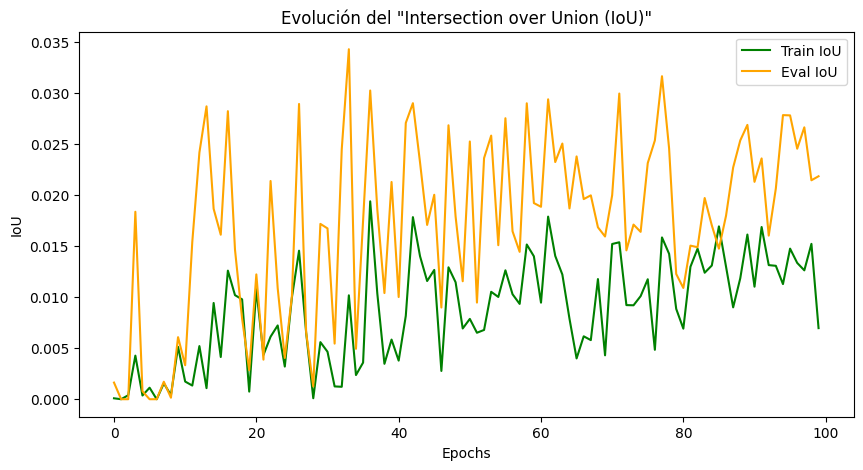

In [87]:
# Evolución del Loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(eval_losses, label='Eval Loss', color='brown')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Evolución del "Loss" ')
plt.legend()
plt.show()

# Evolución del Accuracy
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label='Train Accuracy', color='purple')
plt.plot(eval_accuracies, label='Eval Accuracy', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Evolución de la "Accuracy"')
plt.legend()
plt.show()

# Evolución del IoU
plt.figure(figsize=(10, 5))
plt.plot(train_iou_scores, label='Train IoU', color='green')
plt.plot(eval_iou_scores, label='Eval IoU', color='orange')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.title('Evolución del "Intersection over Union (IoU)"')
plt.legend()
plt.show()

In [88]:
###Preparación Visualización Clases y bboxes predichas VS. Reales

# Cargar el mejor modelo
model.load_state_dict(torch.load('mejor_modelo_pda.pth'))
model.eval()

num_imgs = 8
ncols = 8
nrows = math.ceil(num_imgs / ncols)

start_idx = 0
inference_ds = militarDataset(val_df.iloc[start_idx:start_idx+num_imgs], root_dir=train_root_dir,output_size=(w,h))
inference_data = DataLoader(inference_ds, batch_size=num_imgs, num_workers=1, shuffle=False)
inference_batch = next(iter(inference_data))
inference_imgs = np.empty((num_imgs, 3, 255, 400))

transform = eval_transforms

for i, img in enumerate(inference_batch['image']):
    inference_imgs[i] = transform(dict(image=img.numpy()))['image'].numpy()

preds = model(torch.tensor(inference_imgs).float().to(device))

samples = [inference_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze(), h, w) for s in samples]
classes = [s['class_id'] for s in samples]

# Obtener predicciones del modelo
predicted_bboxes, predicted_labels = model(torch.tensor(inference_imgs).float().to(device))

pred_bboxes = predicted_bboxes.detach().cpu().numpy()
pred_bboxes = [normalize_bbox(bbox, h, w) for bbox in pred_bboxes] # Added h and w arguments
# Get predicted class index for each image
pred_classes = torch.argmax(predicted_labels, dim=1).detach().cpu().numpy()

Imagen 0: bbox real [127, 46, 271, 160], clase real seahawk
Imagen 0: bbox predicha [45, 20, 117, 86], clase predicha cougar


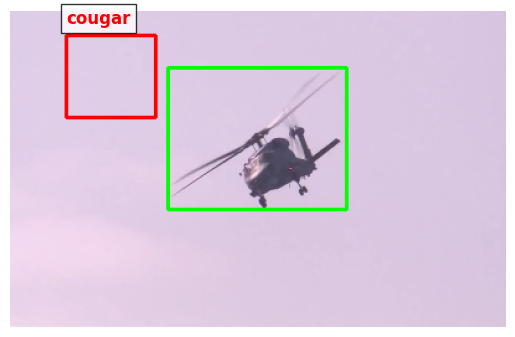

Imagen 1: bbox real [216, 92, 261, 121], clase real f15
Imagen 1: bbox predicha [19, 140, 29, 64], clase predicha ah64


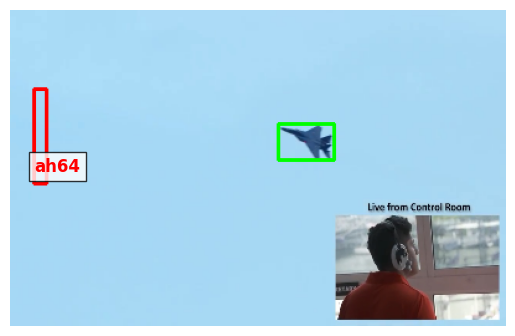

Imagen 2: bbox real [158, 25, 222, 89], clase real f15
Imagen 2: bbox predicha [148, -30, 111, 148], clase predicha f15


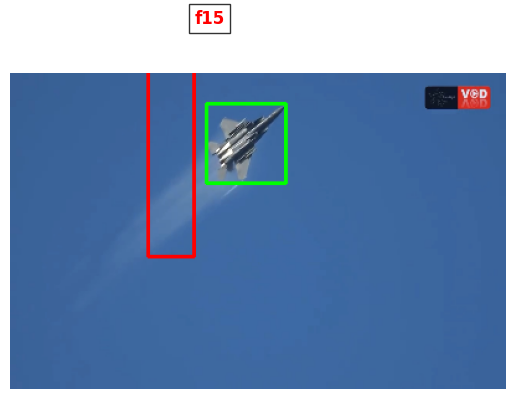

Imagen 3: bbox real [213, 130, 287, 165], clase real chinook
Imagen 3: bbox predicha [85, 33, 202, 112], clase predicha cougar


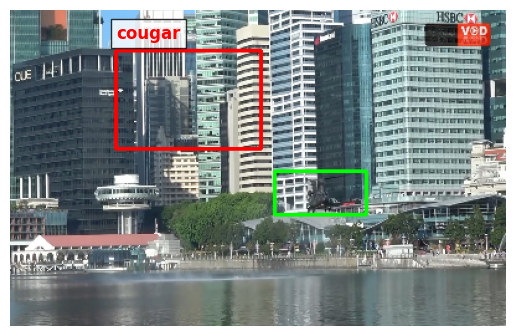

Imagen 4: bbox real [45, 35, 282, 160], clase real cougar
Imagen 4: bbox predicha [83, 32, 198, 110], clase predicha cougar


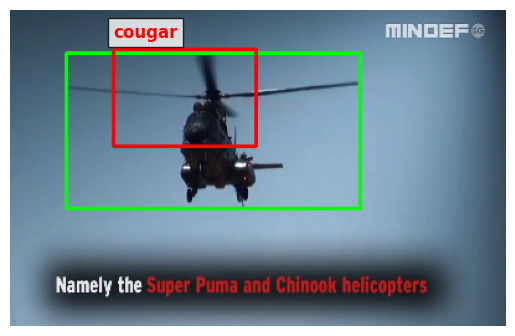

Imagen 5: bbox real [23, 66, 238, 181], clase real cougar
Imagen 5: bbox predicha [70, 37, 155, 107], clase predicha f16


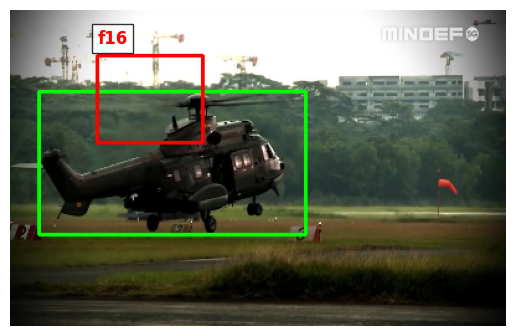

Imagen 6: bbox real [207, 139, 300, 184], clase real chinook
Imagen 6: bbox predicha [79, 30, 183, 102], clase predicha cougar


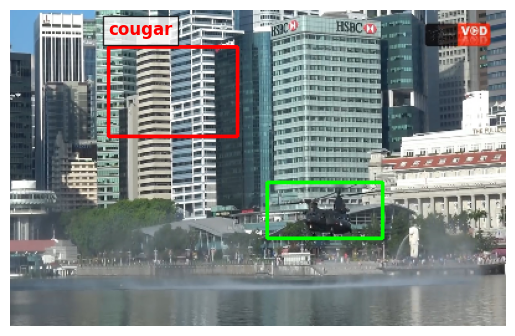

Imagen 7: bbox real [28, 80, 199, 180], clase real f16
Imagen 7: bbox predicha [87, 41, 214, 127], clase predicha f16


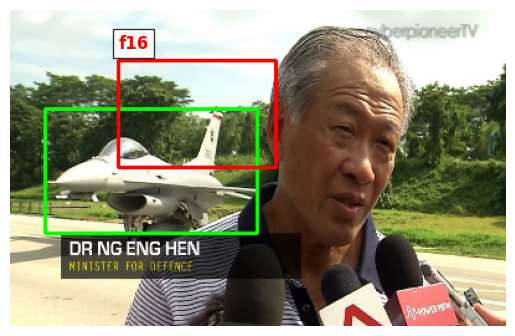

In [89]:
import matplotlib.pyplot as plt

# ... (código anterior para cargar el modelo, hacer predicciones, etc.)

# Usamos id2obj para mapear las clases numéricas a etiquetas textuales
# id2obj = {0: 'f16', 1: 'cougar', 2: 'chinook', 3: 'ah64', 4: 'f15', 5: 'seahawk'}

for i, (img, pred_bbox, pred_class, real_bbox, real_class) in enumerate(zip(imgs, pred_bboxes, pred_classes, bboxes, classes)):
    # Obtener el nombre de la clase predicha usando id2obj
    pred_class_name = id2obj[pred_class]
    real_class_name = id2obj[np.argmax(real_class)] #added line

    print(f"Imagen {i}: bbox real {real_bbox}, clase real {real_class_name}")
    print(f"Imagen {i}: bbox predicha {pred_bbox}, clase predicha {pred_class_name}")

    # Dibuja la bounding box real (verde)
    img_with_bboxes = draw_bbox(img.copy(), real_bbox, color=(0, 255, 0), thickness=2)
    # Dibuja la bounding box predicha (rojo)
    img_with_bboxes = draw_bbox(img_with_bboxes, pred_bbox, color=(255, 0, 0), thickness=2)

    # Agrega una etiqueta con la clase predicha
    plt.imshow(img_with_bboxes)
    plt.text(
        pred_bbox[0],  # Posición x del texto (esquina superior izquierda de la bbox predicha)
        pred_bbox[1] - 10,  # Posición y del texto (un poco arriba de la bbox predicha)
        f'{pred_class_name}',  # Texto a mostrar (nombre de la clase predicha)
        color='red',  # Color del texto
        fontsize=12,  # Tamaño de la fuente
        weight='bold',  # Grosor de la fuente
        bbox=dict(facecolor='white', alpha=0.8)  # Fondo blanco detrás del texto
    )
    plt.axis('off')  # Ocultar los ejes
    plt.show()

📈CONCLUSIONES

Se entrenó nuevamente el modelo CustomCNN incluyendo una estrategia robusta de aumentación de datos mediante Albumentations, con transformaciones como rotación, cambio de brillo y contraste, Cutout, Gaussian noise y ShiftScaleRotate. Estas transformaciones se aplicaron sobre imágenes y bounding boxes con el fin de mejorar la generalización del modelo, aumentar la variabilidad del dataset y reducir el riesgo de sobreajuste observado en versiones anteriores.

El uso de data augmentation en el modelo CustomCNN tuvo un impacto positivo en el desempeño general. Las curvas de pérdida mostraron una rápida convergencia y estabilidad, sin indicios de divergencia entre entrenamiento y validación. Por primera vez, la precisión en validación superó en varias ocasiones a la del entrenamiento, lo que sugiere una mejor capacidad de generalización gracias a la mayor variabilidad introducida por las transformaciones aplicadas. Aunque la accuracy se mantuvo en niveles moderados (40%–60%), representó una mejora clara frente a la versión sin aumentaciones. En cuanto al IoU, si bien sus valores se mantuvieron bajos (~0.02–0.04), se evidenció una mejora ligera pero constante, con mayor estabilidad entre entrenamiento y validación, pero bajo. Aún hay desviaciones extremas

In [90]:
### Preparación Para los Submit
# Change device to 'cpu' if no GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# The rest of your code remains the same
test_root_dir = osp.join(DATA_DIR, "images")
test_df = pd.read_csv(osp.join(DATA_DIR, "test.csv"))

# Asegúrate de que el dataset de prueba tenga las transformaciones adecuadas aplicadas
test_ds = militarDataset(test_df, root_dir=test_root_dir, labeled=False, transform=eval_transforms,output_size=(w,h))#
test_data = DataLoader(test_ds, batch_size=1, num_workers=cpu_count(), shuffle=False)

class_preds = []
bbox_preds = []

# Iterar sobre el conjunto de datos de prueba
for batch in test_data:
    # Mover imágenes al dispositivo correcto
    images = batch['image'].float().to(device)

    # Obtener predicciones del modelo
    predicted_bboxes, predicted_labels = model(images)

    # Get the predicted class index
    _, predicted_class_index = torch.max(predicted_labels, 1)

    # Create one-hot encoding for predicted class
    class_pred_binario = torch.zeros(6)  # 6 classes
    class_pred_binario[predicted_class_index] = 1
    class_pred_binario = class_pred_binario.detach().cpu().numpy()

    # Extraer las predicciones de las bounding boxes y mover a CPU
    bbox_pred = predicted_bboxes.detach().cpu().numpy()

    # Aplanar las predicciones si están en un lote de tamaño 1
    class_preds.append(class_pred_binario.squeeze())
    bbox_preds.append(bbox_pred.squeeze())

In [91]:
class_preds = np.array(class_preds)
bbox_preds = np.array(bbox_preds)

In [92]:
submission = pd.DataFrame(
    index=test_df.filename,
    data={
        'class_id': [np.argmax(pred) for pred in class_preds], # Get the index of the highest probability for each image
    }
)
submission

,class_id
filename,
image_00219.jpeg,1
image_00034.jpeg,0
image_00265.jpeg,1
image_00042.jpeg,0
image_00294.jpeg,3
...,...
image_00035.jpeg,0
image_00071.jpeg,1
image_00099.jpeg,1


In [93]:
submission["xmin"] = bbox_preds[:, 0]*w_real
submission["ymin"] = bbox_preds[:, 1]*h_real
submission["xmax"] = bbox_preds[:, 2]*w_real
submission["ymax"] = bbox_preds[:, 3]*h_real

In [94]:
submission['class_id']=submission['class_id'].replace(id2obj)

In [95]:
submission.to_csv('/content/drive/MyDrive/FA/submissionintentov3_Intu.csv')

In [96]:
##Limpiar Cache
torch.cuda.empty_cache()

###✅MODELO DE TRASNFER LEARNING + DATA AUGMENTATION

In [97]:
#### Modelo TransferLearning
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DualBackboneModel().to(device)
model

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most u

DualBackboneModel(
  (backbone1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running

In [98]:
import torch.optim.lr_scheduler as lr_scheduler

# Parámetros rebalanceo pérdidas
alpha = 10.0  # Peso bbox loss
beta = 1.0    # Peso clasificación

# Pesos para métrica compuesta en guardado
w_acc = 0.7
w_iou = 0.3
mejor_score = -float('inf')

# Definición las funciones de pérdida
bbox_loss_fn = nn.SmoothL1Loss()
classification_loss_fn = nn.CrossEntropyLoss()

# Optimizador
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

# Scheduler para reducir lr si no mejora validación
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, verbose=True)

# Inicialización variables métricas
train_iou_sum = 0
eval_iou_sum = 0
train_losses = []
train_accuracies = []
eval_losses = []
eval_accuracies = []
train_iou_scores = []
eval_iou_scores = []

num_epochs = 200
print_interval = 20

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    for batch in train_data_t:
        images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
        images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

        predicted_bboxes, predicted_labels = model(images)

        if bboxes.dim() == 3 and bboxes.size(1) == 1:
            bboxes = bboxes.squeeze(1)

        loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
        loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))

        total_loss = alpha * loss_bbox + beta * loss_classification

        _, predicted_classes = torch.max(predicted_labels, 1)
        correct_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
        total_predictions += labels.size(0)

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item()

    epoch_loss = running_loss / len(train_data_t)
    epoch_accuracy = correct_predictions / total_predictions
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    iou = calculate_iou(predicted_bboxes, bboxes)
    train_iou_sum += iou.sum().item()
    train_iou = train_iou_sum / total_predictions
    train_iou_scores.append(train_iou)

    model.eval()
    eval_loss = 0.0
    correct_eval_predictions = 0
    total_eval_predictions = 0

    with torch.no_grad():
        for batch in eval_data:
            images, bboxes, labels = batch['image'], batch['bbox'], batch['class_id']
            images, bboxes, labels = images.to(device), bboxes.to(device), labels.to(device)

            predicted_bboxes, predicted_labels = model(images)

            if bboxes.dim() == 3 and bboxes.size(1) == 1:
                bboxes = bboxes.squeeze(1)

            loss_bbox = bbox_loss_fn(predicted_bboxes, bboxes)
            loss_classification = classification_loss_fn(predicted_labels, labels.argmax(dim=1))
            total_loss_eval = alpha * loss_bbox + beta * loss_classification

            _, predicted_classes = torch.max(predicted_labels, 1)
            correct_eval_predictions += (predicted_classes == labels.argmax(dim=1)).sum().item()
            total_eval_predictions += labels.size(0)

            eval_loss += total_loss_eval.item()

    eval_loss_avg = eval_loss / len(eval_data)
    eval_losses.append(eval_loss_avg)
    eval_accuracy = correct_eval_predictions / total_eval_predictions
    eval_accuracies.append(eval_accuracy)

    iou = calculate_iou(predicted_bboxes, bboxes)
    eval_iou_sum += iou.sum().item()
    eval_iou = eval_iou_sum / total_eval_predictions
    eval_iou_scores.append(eval_iou)

    # Scheduler ajusta lr según pérdida validación
    scheduler.step(eval_loss_avg)

    # Métrica compuesta para guardado
    score = w_acc * eval_accuracy + w_iou * eval_iou

    if score > mejor_score:
        mejor_score = score
        torch.save(model.state_dict(), 'mejor_modelo_rnda.pth')

    if (epoch + 1) % print_interval == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}] => '
              f'Train loss bbox: {loss_bbox.item():.4f}, Train loss class: {loss_classification.item():.4f}, '
              f'Train total loss: {epoch_loss:.4f}, Train accuracy: {epoch_accuracy:.4f}, Train IoU: {train_iou:.4f}, '
              f'Eval loss: {eval_loss_avg:.4f}, Eval accuracy: {eval_accuracy:.4f}, Eval IoU: {eval_iou:.4f}, '
              f'Composite score: {score:.4f}')

    train_iou_sum = 0
    eval_iou_sum = 0

print("¡Entrenamiento Completo!")



/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch [20/200] => Train loss bbox: 0.0041, Train loss class: 1.2574, Train total loss: 1.3610, Train accuracy: 0.7884, Train IoU: 0.0617, Eval loss: 1.2709, Eval accuracy: 0.8333, Eval IoU: 0.1361, Composite score: 0.6242
Epoch [40/200] => Train loss bbox: 0.0021, Train loss class: 1.0528, Train total loss: 1.1592, Train accuracy: 0.9471, Train IoU: 0.0719, Eval loss: 1.0733, Eval accuracy: 1.0000, Eval IoU: 0.1556, Composite score: 0.7467
Epoch [60/200] => Train loss bbox: 0.0008, Train loss class: 1.0441, Train total loss: 1.0932, Train accuracy: 0.9947, Train IoU: 0.0806, Eval loss: 1.0530, Eval accuracy: 1.0000, Eval IoU: 0.2207, Composite score: 0.7662
Epoch [80/200] => Train loss bbox: 0.0007, Train loss class: 1.0439, Train total loss: 1.0758, Train accuracy: 0.9947, Train IoU: 0.0929, Eval loss: 1.0512, Eval accuracy: 1.0000, Eval IoU: 0.2231, Composite score: 0.7669
Epoch [100/200] => Train loss bbox: 0.0006, Train loss class: 1.0439, Train total loss: 1.0683, Train accuracy: 

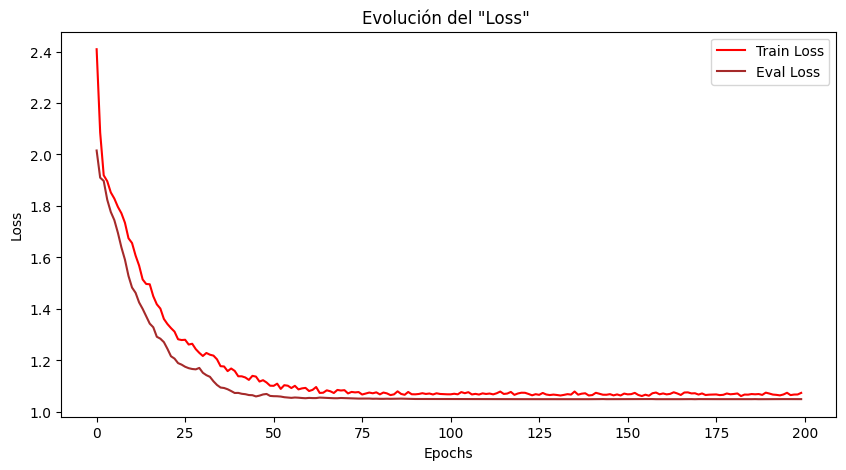

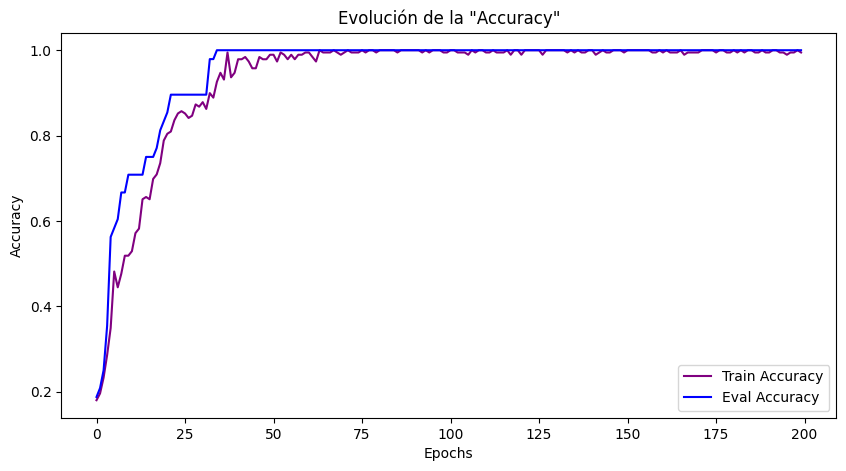

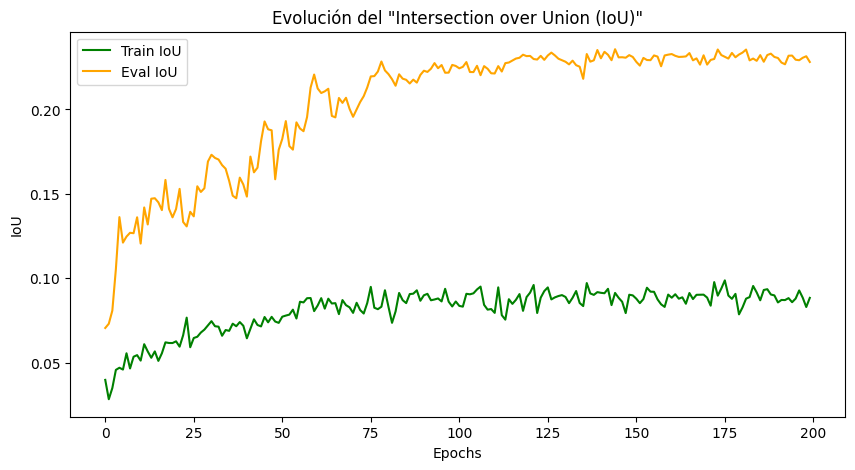

In [99]:
# Evolución del Loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='red')
plt.plot(eval_losses, label='Eval Loss', color='brown')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Evolución del "Loss" ')
plt.legend()
plt.show()

# Evolución del Accuracy
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label='Train Accuracy', color='purple')
plt.plot(eval_accuracies, label='Eval Accuracy', color='blue')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Evolución de la "Accuracy"')
plt.legend()
plt.show()

# Evolución del IoU
plt.figure(figsize=(10, 5))
plt.plot(train_iou_scores, label='Train IoU', color='green')
plt.plot(eval_iou_scores, label='Eval IoU', color='orange')
plt.xlabel('Epochs')
plt.ylabel('IoU')
plt.title('Evolución del "Intersection over Union (IoU)"')
plt.legend()
plt.show()

In [100]:
###Preparación Visualización Clases y bboxes predichas VS. Reales

# Cargar el mejor modelo
model.load_state_dict(torch.load('mejor_modelo_rnda.pth'))
model.eval()

num_imgs = 8
ncols = 8
nrows = math.ceil(num_imgs / ncols)

start_idx = 0
inference_ds = militarDataset(val_df.iloc[start_idx:start_idx+num_imgs], root_dir=train_root_dir,output_size=(w,h))
inference_data = DataLoader(inference_ds, batch_size=num_imgs, num_workers=1, shuffle=False)
inference_batch = next(iter(inference_data))
inference_imgs = np.empty((num_imgs, 3, 255, 400))

transform = eval_transforms

for i, img in enumerate(inference_batch['image']):
    inference_imgs[i] = transform(dict(image=img.numpy()))['image'].numpy()

preds = model(torch.tensor(inference_imgs).float().to(device))

samples = [inference_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze(), h, w) for s in samples]
classes = [s['class_id'] for s in samples]

# Obtener predicciones del modelo
predicted_bboxes, predicted_labels = model(torch.tensor(inference_imgs).float().to(device))

pred_bboxes = predicted_bboxes.detach().cpu().numpy()
pred_bboxes = [normalize_bbox(bbox, h, w) for bbox in pred_bboxes] # Added h and w arguments
# Get predicted class index for each image
pred_classes = torch.argmax(predicted_labels, dim=1).detach().cpu().numpy()

Imagen 0: bbox real [127, 46, 271, 160], clase real seahawk
Imagen 0: bbox predicha [132, 39, 289, 171], clase predicha seahawk


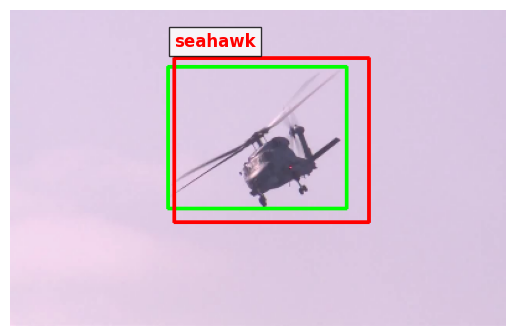

Imagen 1: bbox real [216, 92, 261, 121], clase real f15
Imagen 1: bbox predicha [220, 97, 241, 116], clase predicha f15


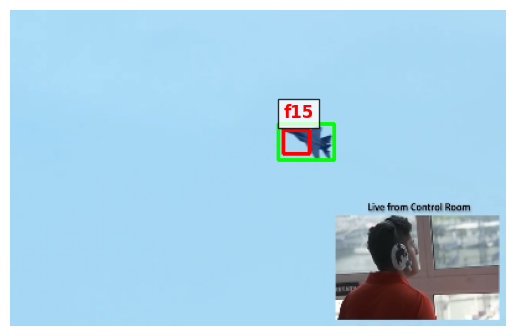

Imagen 2: bbox real [158, 25, 222, 89], clase real f15
Imagen 2: bbox predicha [148, 8, 215, 79], clase predicha f15


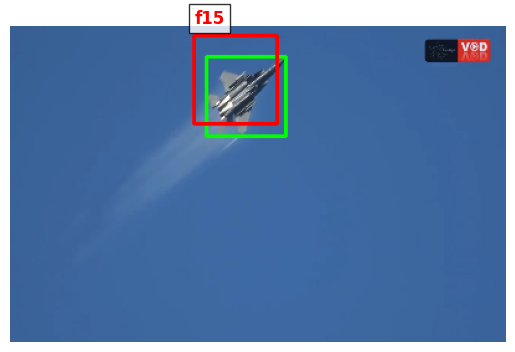

Imagen 3: bbox real [213, 130, 287, 165], clase real chinook
Imagen 3: bbox predicha [217, 138, 287, 178], clase predicha chinook


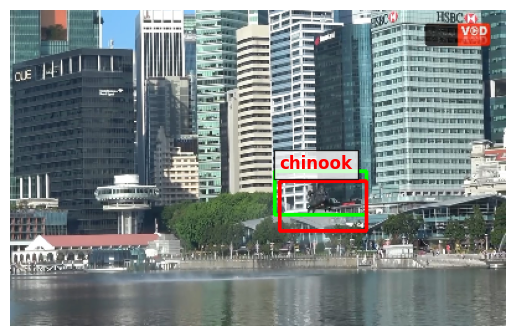

Imagen 4: bbox real [45, 35, 282, 160], clase real cougar
Imagen 4: bbox predicha [42, 26, 266, 155], clase predicha cougar


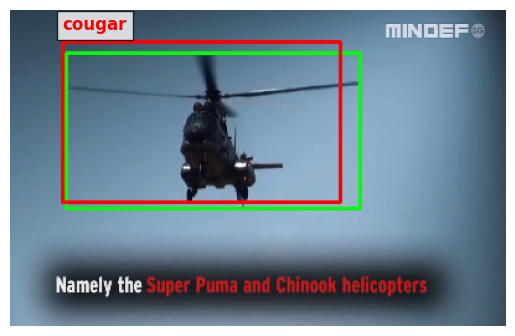

Imagen 5: bbox real [23, 66, 238, 181], clase real cougar
Imagen 5: bbox predicha [8, 79, 236, 176], clase predicha cougar


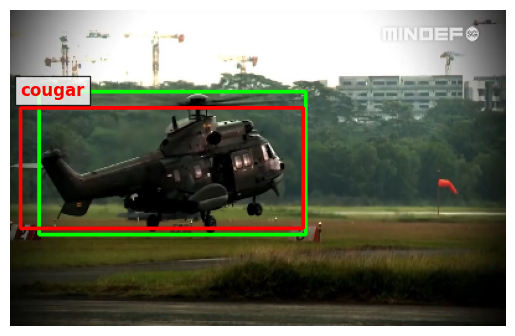

Imagen 6: bbox real [207, 139, 300, 184], clase real chinook
Imagen 6: bbox predicha [209, 127, 301, 176], clase predicha chinook


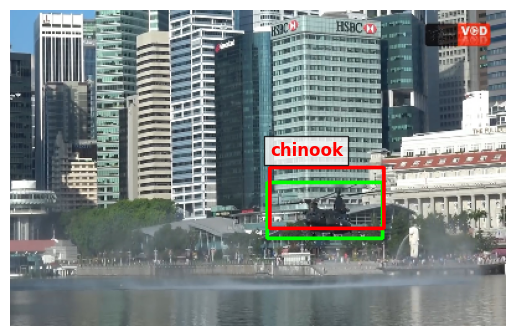

Imagen 7: bbox real [28, 80, 199, 180], clase real f16
Imagen 7: bbox predicha [54, 76, 214, 180], clase predicha f16


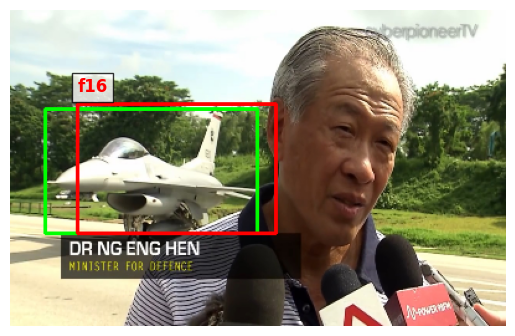

In [101]:
import matplotlib.pyplot as plt

# ... (código anterior para cargar el modelo, hacer predicciones, etc.)

# Usamos id2obj para mapear las clases numéricas a etiquetas textuales
# id2obj = {0: 'f16', 1: 'cougar', 2: 'chinook', 3: 'ah64', 4: 'f15', 5: 'seahawk'}

for i, (img, pred_bbox, pred_class, real_bbox, real_class) in enumerate(zip(imgs, pred_bboxes, pred_classes, bboxes, classes)):
    # Obtener el nombre de la clase predicha usando id2obj
    pred_class_name = id2obj[pred_class]
    real_class_name = id2obj[np.argmax(real_class)] #added line

    print(f"Imagen {i}: bbox real {real_bbox}, clase real {real_class_name}")
    print(f"Imagen {i}: bbox predicha {pred_bbox}, clase predicha {pred_class_name}")

    # Dibuja la bounding box real (verde)
    img_with_bboxes = draw_bbox(img.copy(), real_bbox, color=(0, 255, 0), thickness=2)
    # Dibuja la bounding box predicha (rojo)
    img_with_bboxes = draw_bbox(img_with_bboxes, pred_bbox, color=(255, 0, 0), thickness=2)

    # Agrega una etiqueta con la clase predicha
    plt.imshow(img_with_bboxes)
    plt.text(
        pred_bbox[0],  # Posición x del texto (esquina superior izquierda de la bbox predicha)
        pred_bbox[1] - 10,  # Posición y del texto (un poco arriba de la bbox predicha)
        f'{pred_class_name}',  # Texto a mostrar (nombre de la clase predicha)
        color='red',  # Color del texto
        fontsize=12,  # Tamaño de la fuente
        weight='bold',  # Grosor de la fuente
        bbox=dict(facecolor='white', alpha=0.8)  # Fondo blanco detrás del texto
    )
    plt.axis('off')  # Ocultar los ejes
    plt.show()

📈CONCLUSIONES

Se entrenó un modelo avanzado de detección multiclase implementado con transferencia de aprendizaje, combinando ResNet18 y EfficientNet-B0 como doble backbone. Se aplicaron estrategias de data augmentation, además de un rebalanceo de la función de pérdida, priorizando la precisión en la predicción de bounding boxes mediante un peso α=10 sobre la pérdida de regresión.

Las curvas de loss evidencian una convergencia sostenida desde las primeras épocas, alcanzando estabilidad a partir de la época 50 con mínimas diferencias entre entrenamiento y validación, lo que descarta posiblemente presencia de sobreajuste. Accuracy alcanzó valores cercanos al 100% tanto en entrenamiento como en validación, manteniéndose alineada durante las 200 épocas, buena capacidad del modelo para clasificar correctamente las clases. En cuanto a localización, el modelo mostró una mejora sustancial con un IoU promedio de 0.22 en validación, superando con amplitud a versiones anteriores y demostrando una mejor precisión espacial gracias al rebalanceo de las funciones de pérdida. Las visualizaciones confirman que las predicciones son cercanas en la mayoría de los casos, tanto en clases como en cajas. En conjunto, la combinación de data augmentation, transfer learning y ajuste de ponderaciones permitió obtener un modelo mejor

In [102]:
### Preparación Para los Submit
# Change device to 'cpu' if no GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# The rest of your code remains the same
test_root_dir = osp.join(DATA_DIR, "images")
test_df = pd.read_csv(osp.join(DATA_DIR, "test.csv"))

# Asegúrate de que el dataset de prueba tenga las transformaciones adecuadas aplicadas
test_ds = militarDataset(test_df, root_dir=test_root_dir, labeled=False, transform=eval_transforms,output_size=(w,h))#
test_data = DataLoader(test_ds, batch_size=1, num_workers=cpu_count(), shuffle=False)

class_preds = []
bbox_preds = []

# Iterar sobre el conjunto de datos de prueba
for batch in test_data:
    # Mover imágenes al dispositivo correcto
    images = batch['image'].float().to(device)

    # Obtener predicciones del modelo
    predicted_bboxes, predicted_labels = model(images)

    # Get the predicted class index
    _, predicted_class_index = torch.max(predicted_labels, 1)

    # Create one-hot encoding for predicted class
    class_pred_binario = torch.zeros(6)  # 6 classes
    class_pred_binario[predicted_class_index] = 1
    class_pred_binario = class_pred_binario.detach().cpu().numpy()

    # Extraer las predicciones de las bounding boxes y mover a CPU
    bbox_pred = predicted_bboxes.detach().cpu().numpy()

    # Aplanar las predicciones si están en un lote de tamaño 1
    class_preds.append(class_pred_binario.squeeze())
    bbox_preds.append(bbox_pred.squeeze())

In [103]:
class_preds = np.array(class_preds)
bbox_preds = np.array(bbox_preds)

In [104]:
submission = pd.DataFrame(
    index=test_df.filename,
    data={
        'class_id': [np.argmax(pred) for pred in class_preds], # Get the index of the highest probability for each image
    }
)
submission

,class_id
filename,
image_00219.jpeg,2
image_00034.jpeg,0
image_00265.jpeg,3
image_00042.jpeg,0
image_00294.jpeg,3
...,...
image_00035.jpeg,0
image_00071.jpeg,1
image_00099.jpeg,2


In [105]:
submission["xmin"] = bbox_preds[:, 0]*w_real
submission["ymin"] = bbox_preds[:, 1]*h_real
submission["xmax"] = bbox_preds[:, 2]*w_real
submission["ymax"] = bbox_preds[:, 3]*h_real

In [106]:
submission['class_id']=submission['class_id'].replace(id2obj)

In [107]:
submission.to_csv('/content/drive/MyDrive/FA/submissionyala4_Intu.csv')